# Stuck-bayes: which parts does it need?

`stuck-bayes` is the best teacher family so far in the costly condition (agency 0, so shown moves aren't learned
from, with skipped update steps; see `rush_hour_sweep.ipynb`). It has two parts:

- **When:** a gate. It stays out until the student has made `patience` x the puzzle's optimal length moves of its own
  without getting closer to the goal than ever before.
- **How much:** a Bayesian model of the student. Once the gate is open, it shows the optimal move whenever the model
  gives the student less than `theta` chance of solving alone from here. It stops when the chance is back, steps
  straight back in if the student slides, and the gate closes at the student's next new closest approach.

This notebook strips it down, one component at a time, toward the most parsimonious teacher that keeps its learning.
All runs are added to the sweep's agency-0 run (`teach_shortcut_agency0`), so every student is the same across
teachers and comparisons are paired by student.

**First comparison: does the model's calibration matter?** `stuck-bayes` uses the calibrated model (bayes2's: a
move's chance of being optimal depends on its distance to the goal *and* from the puzzle's start, evidence kept for
1,000 puzzles). `stuck-bayes1` uses the original one (bayes's: distance to the goal only, evidence kept for 300
puzzles, too optimistic about long puzzles). As plain Bayesian teachers the miscalibrated original taught better
(bayes 3% beat bayes2 4.5% by 0.14) - it stepped in later. With the stuck gate fixing the timing for both, is the
calibration still worth anything?

`stuck-bayes1 0.25` matches `stuck-bayes 0.3`'s spend in a mini test (2 students x 80 puzzles: 4.4% against 4.5%).
If the two tie, the next step is the full spectrum of help (a theta sweep for both) before dropping the calibration.

In [1]:
import sys
sys.path.append("../scripts")
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import run_queue as rq
import session_experiment as se
import teach_experiment as te

OUT = se.OUT
FIGURES = "../visualization"
RUN = "teach_shortcut_agency0"  # every teacher here plays in the sweep's agency-0 run
NONE_RUN = "teach_shortcut_agency0.3"  # no teacher: the same at every agency, saved in the agency-0.3 run
# The run's settings (rush_hour_sweep.ipynb: START | shortcut labels | agency 0 with skipped steps).
SETTINGS = {"students": 8, "session_bins": ["9-11", "14-16", "19-21", "24-26"], "multiplier": 30, "per_bin": 18,
            "lr": 1e-4, "window": -1, "steps": 3, "max_attempts": 1, "surrender": True, "surrender_scale": 0.4,
            "test_per_bin": 50, "init": "../models/teach/fresh_p0.1/random_0.1/round6_epoch01.pt", "labels": "all",
            "shown_weight": 0.0, "agency_step": "skip"}


def argv(settings):
    """session_experiment's command line (after the run name) for these settings."""
    out = []
    for k, v in settings.items():
        flag = "--" + k.replace("_", "-")
        if isinstance(v, bool):
            out += [flag] if v else []
        elif isinstance(v, list):
            out += [flag, *map(str, v)]
        else:
            out += [flag, str(v)]
    return out


def launch(queue, teachers, run=RUN, settings=SETTINGS):
    """Plays `teachers` (specs) in `run` in the background (run_queue); does nothing for teachers already saved."""
    os.chdir("../scripts")  # the runs resolve relative paths (--init) from scripts/
    try:
        rq.launch(queue, [(run, argv(settings) + ["--teachers", *teachers])])
    finally:
        os.chdir("../notebooks")


def watch(queue):
    if os.path.exists(os.path.join(OUT, "queues", f"{queue}.json")):
        rq.watch(queue)  # refreshes every 30 s until the queue stops
    else:
        print(f"{queue} hasn't been launched")


def entry(run, spec):
    """A teacher's entry in a run ({"config", "sessions", "results"}), or None until it is saved."""
    if not os.path.exists(os.path.join(OUT, run, "config.json")):
        return None
    loaded = se.load_session(run, OUT)
    found = loaded["teachers"].get(se.teacher_name(spec))
    if not found or not found["sessions"] or not found["results"]:
        return None
    return {"config": loaded["config"], **found}


def measures(attempts, config):
    """(score, solve rate, moves / optimal over solved attempts) of test attempts; score: moves / optimal with an
    unsolved attempt counted at its move cap (lower is better)."""
    score = [(a["moves"] if a["solved"] else te.step_cap(a["distance"], config)) / a["distance"] for a in attempts]
    solved = [a["moves"] / a["distance"] for a in attempts if a["solved"]]
    return np.mean(score), np.mean([a["solved"] for a in attempts]), np.mean(solved) if solved else np.nan


def curve(e):
    """[(puzzles played, (mean test score, standard error across students))] along the session."""
    points = sorted({n for by_n in e["results"].values() for n in by_n})
    return [(n, te.mean_se([measures(by_n[n], e["config"])[0] for by_n in e["results"].values() if n in by_n]))
            for n in points]


def final(e):
    """{student: (score, solve rate, moves / optimal over solved)} at the end of the session."""
    return {s: measures(by_n[max(by_n)], e["config"]) for s, by_n in e["results"].items()}


def learning(e):
    """Each student's test score gain over the session (all students start from the same network)."""
    start = measures(e["results"][0][0], e["config"])[0]
    return [start - v[0] for v in final(e).values()]


def paired(e, base):
    """End score minus `base`'s, student by student: "mean ± se (k/n better)"; below 0: e's students learned more."""
    end, b = final(e), final(base)
    d = [end[s][0] - b[s][0] for s in end if s in b]
    m, s = te.mean_se(d)
    return f"{m:+.3f} ± {s:.3f} ({sum(x < 0 for x in d)}/{len(d)})"


def teacher_table(specs, against, run=RUN):
    """Spend, solves, how help was given, learning, and the end score against each of `against` (specs), paired
    by student."""
    rows = []
    for spec in specs:
        e = entry(run, spec)
        if e is None:
            print(f"{se.teacher_name(spec)}: not saved yet")
            continue
        records = [x for record in e["sessions"].values() for x in record]
        helped = [x for x in records if x["taught"] > 0]
        m, s = te.mean_se(learning(e))
        row = {"teacher": se.teacher_name(spec),
               "shown": sum(x["taught"] for x in records) / sum(x["moves"] for x in records),
               "solved as played": np.mean([x["solved"] for x in records]),
               "helped puzzles": len(helped) / len(records),
               "shown per helped": np.mean([x["taught"] for x in helped]) if helped else np.nan,
               "helped solved": np.mean([x["solved"] for x in helped]) if helped else np.nan,
               "own moves on helped": np.mean([x["moves"] - x["taught"] for x in helped]) if helped else np.nan,
               "learning": f"{m:+.3f} ± {s:.3f}"}
        for other in against:
            base = entry(run, other)
            row[f"vs {se.teacher_name(other)}"] = paired(e, base) if base is not None and other != spec else ""
        rows.append(row)
    return pd.DataFrame(rows).round(3)

## Run: stuck-bayes1 0.25 (patience 1)

One teacher run, about 25 minutes on the PC. `stuck-bayes 0.3` and the other references are already saved in the
run. Launching again does nothing while the queue runs or once it is saved.

In [2]:
CALIBRATION = ["stuck-bayes1:0.25"]
launch("stuck_bayes1", CALIBRATION)

stuck_bayes1: all 1 teacher runs are saved, nothing to play


In [3]:
watch("stuck_bayes1")

c:\dev\GitHub\rush-hour\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
stuck_bayes1: 100%|██████████| , finished: 1.0/1 teacher runs in 26m


## Results

Learning is the test score gain over the session (no teacher: about +1.43). The paired columns are the end score
minus the other teacher's, student by student: below 0 means this teacher's students learned more.

In [4]:
REFERENCE = ["random:0.045", "bayes:0.03", "bayes2:0.045", "stuck-bayes:0.3", "stuck-bayes:0.12,patience=0.5"]
display(teacher_table(REFERENCE + CALIBRATION, against=["stuck-bayes:0.3", "stuck-bayes:0.12,patience=0.5", "bayes:0.03",
                                                          "random:0.045"]))

,teacher,shown,solved as played,helped puzzles,shown per helped,helped solved,own moves on helped,learning,vs stuck-bayes 0.3,vs stuck-bayes 0.12 p0.5,vs bayes 0.03,vs random 0.045
0,random 0.045,0.045,0.761,0.781,3.706,0.717,72.490,+1.548 ± 0.037,+0.220 ± 0.103 (3/8),+0.268 ± 0.073 (0/8),+0.271 ± 0.072 (1/8),
1,bayes 0.03,0.030,0.863,0.189,9.460,0.954,118.852,+1.819 ± 0.045,-0.051 ± 0.063 (3/8),-0.003 ± 0.039 (3/8),,-0.271 ± 0.072 (7/8)
2,bayes2 0.045,0.044,0.887,0.268,9.094,0.939,94.031,+1.679 ± 0.039,+0.088 ± 0.064 (3/8),+0.137 ± 0.040 (1/8),+0.139 ± 0.034 (1/8),-0.132 ± 0.073 (5/8)
3,stuck-bayes 0.3,0.045,0.851,0.216,12.095,0.744,120.876,+1.768 ± 0.076,,+0.048 ± 0.067 (4/8),+0.051 ± 0.063 (5/8),-0.220 ± 0.103 (5/8)
4,stuck-bayes 0.12 p0.5,0.036,0.823,0.183,12.468,0.647,143.559,+1.816 ± 0.046,-0.048 ± 0.067 (4/8),,+0.003 ± 0.039 (5/8),-0.268 ± 0.073 (8/8)
5,stuck-bayes1 0.25,0.033,0.836,0.176,11.669,0.700,151.306,+1.892 ± 0.047,-0.124 ± 0.088 (4/8),-0.076 ± 0.044 (5/8),-0.073 ± 0.058 (5/8),-0.344 ± 0.053 (8/8)


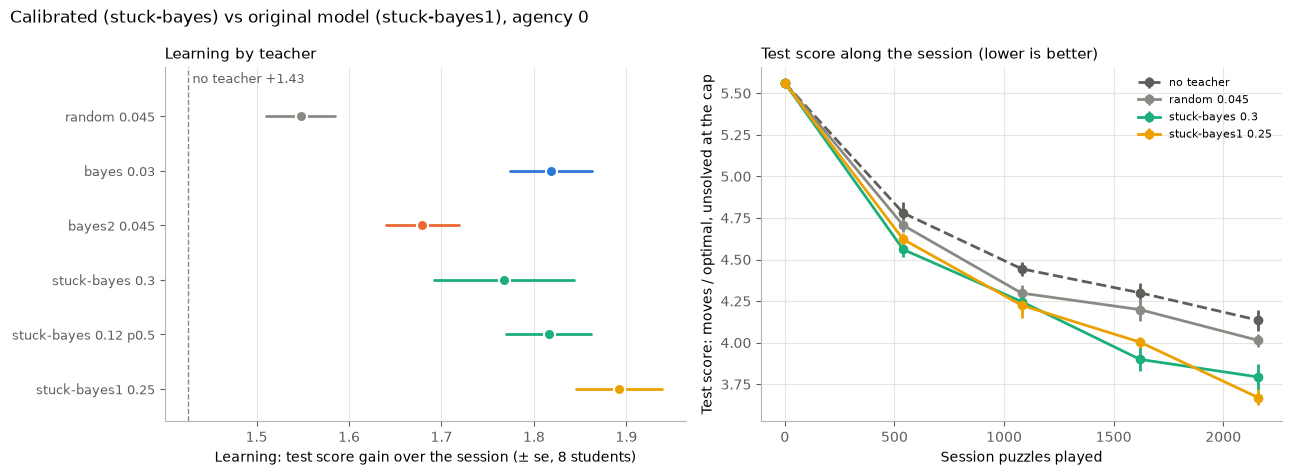

In [5]:
COLORS = {"random:0.045": "#8a8a85", "bayes:0.03": "#2a78d6", "bayes2:0.045": "#eb6834",
          "stuck-bayes:0.3": "#1baf7a", "stuck-bayes:0.12,patience=0.5": "#1baf7a", "stuck-bayes1:0.25": "#eda100"}


def calibration_figure(specs, curves, path):
    """Left: learning ± se per teacher, no teacher as the dashed line. Right: the test score along the session for
    `curves` (lower is better). Saved to `path`."""
    none = entry(NONE_RUN, "none")
    base = np.mean(learning(none))
    rows = [(se.teacher_name(s), *te.mean_se(learning(e)), COLORS[s]) for s in specs
            if (e := entry(RUN, s)) is not None]
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), width_ratios=[1, 1])
    y = np.arange(len(rows))[::-1]
    for (name, m, s, c), yy in zip(rows, y):
        ax.plot([m - s, m + s], [yy, yy], color=c, lw=2, solid_capstyle="round")
        ax.plot(m, yy, "o", ms=8, color=c, mec="white", mew=1.5)
    ax.axvline(base, color="#8a8a85", lw=1, ls="--", zorder=0)
    ax.text(base, y[0] + 0.55, f" no teacher {base:+.2f}", color="#5f5e5a", fontsize=9, va="bottom")
    ax.set_yticks(y, [r[0] for r in rows], fontsize=9)
    ax.set_ylim(-0.6, len(rows) - 0.1)
    ax.set_xlabel("Learning: test score gain over the session (± se, 8 students)")
    ax.set_title("Learning by teacher", fontsize=11, loc="left")

    for spec in curves:
        e = entry(NONE_RUN, spec) if spec == "none" else entry(RUN, spec)
        if e is None:
            continue
        points = curve(e)
        c = "#5f5e5a" if spec == "none" else COLORS[spec]
        ax2.errorbar([n for n, _ in points], [m for _, (m, _) in points], yerr=[s for _, (_, s) in points],
                     marker="o", ms=6, lw=2, capsize=0, color=c, ls="--" if spec == "none" else "-",
                     label="no teacher" if spec == "none" else se.teacher_name(spec))
    ax2.set_xlabel("Session puzzles played")
    ax2.set_ylabel("Test score: moves / optimal, unsolved at the cap")
    ax2.set_title("Test score along the session (lower is better)", fontsize=11, loc="left")
    ax2.legend(fontsize=8, frameon=False)
    for a in (ax, ax2):
        a.grid(axis="x" if a is ax else "both", color="#e6e5e0", lw=0.8)
        a.set_axisbelow(True)
        for side in ("top", "right"):
            a.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            a.spines[side].set_color("#b5b4ad")
        a.tick_params(colors="#5f5e5a")
    fig.suptitle("Calibrated (stuck-bayes) vs original model (stuck-bayes1), agency 0", x=0.01, ha="left", fontsize=12)
    plt.tight_layout()
    os.makedirs(os.path.dirname(path), exist_ok=True)
    plt.savefig(path, dpi=150)
    plt.show()


calibration_figure(REFERENCE + CALIBRATION, ["none", "random:0.045", "stuck-bayes:0.3"] + CALIBRATION,
                   os.path.join(FIGURES, "stuck_bayes_calibration.png"))

### Result: the original model is at least as good (2026-11-08, agency 0, 8 students, on the PC)

| teacher | shown | solved | helped puzzles | own moves on helped | learning | vs stuck-bayes 0.3 | vs stuck-bayes 0.12 p0.5 | vs bayes 0.03 | vs random 4.5% |
|---|---|---|---|---|---|---|---|---|---|
| stuck-bayes 0.3 | 4.5% | 0.85 | 22% | 121 | +1.77 ± 0.08 | - | +0.05 ± 0.07 | +0.05 ± 0.06 | −0.22 ± 0.10 (5/8) |
| stuck-bayes 0.12 p0.5 | 3.6% | 0.82 | 18% | 144 | +1.82 ± 0.05 | −0.05 ± 0.07 | - | +0.00 ± 0.04 | −0.27 ± 0.07 (8/8) |
| **stuck-bayes1 0.25** | 3.3% | 0.84 | 18% | 151 | **+1.89 ± 0.05** | −0.12 ± 0.09 (4/8) | −0.08 ± 0.04 (5/8) | −0.07 ± 0.06 (5/8) | **−0.34 ± 0.05 (8/8)** |

- **Highest learning of any teacher so far** (+1.89), and the clearest win over random 4.5% (8/8 students).
- **Not matched on spend.** The mini test put it at 4.4%; over the full session it showed 3.3%, falling from 3.6% in
  the first quarter to 3.0% in the last (stuck-bayes 0.3: 4.8% to 4.0%). The original model is more optimistic
  (it gave the student a 0.82 chance of solving alone at the start of a puzzle, the calibrated one 0.77), so it steps
  in later (151 of the student's own moves on helped puzzles, against 121) and on fewer puzzles. The same pattern as
  bayes against bayes2.
- **Against its nearest match on spend,** stuck-bayes 0.12 p0.5 (3.6%, calibrated, earlier gate): −0.08 ± 0.04, 5/8
  students. Suggestive, not conclusive.
- **The lead rests on the last test.** Along the session the two curves cross: stuck-bayes 0.3 is ahead at 1,620
  puzzles, stuck-bayes1 only at the end (2,160). One test point carries a lot of test noise.
- **Every length bin** points the same way (end score, stuck-bayes1 − stuck-bayes 0.3: −0.10, −0.10, −0.15, −0.16
  from the shortest bin to the longest), each within its standard error.

**So the calibration isn't needed** - nothing here favours the calibrated model, and the simpler original one (one
term per distance to the goal instead of two sets) did at least as well. Whether it is *better*, or only spent less,
can't be told from one run: the three best teachers (stuck-bayes1 0.25, stuck-bayes 0.12 p0.5, bayes 0.03) all
show 3.0-3.6% and step in late. That points the help sweep **downward**: theta values for both models that span
about 2-6% spend, so each model's peak is found rather than assumed near 4.5%.

## The help sweep: each model's best amount of help

At agency 0 help has a built-in cost, so learning rises and then falls with the amount shown (random: +1.49 at 3%,
+1.55 at 4.5%, +1.63 at 10%, +1.32 at 30%, +0.00 at 100%). The fair comparison is each teacher at its own best
amount, not at one shared spend. So both models get the same theta grid at patience 1, and learning is plotted
against the spend each run actually reached:

| theta | stuck-bayes (calibrated) | stuck-bayes1 (original) |
|---|---|---|
| 0.1 | new | new |
| 0.25 / 0.3 | saved (0.3: 4.5%) | saved (0.25: 3.3%) |
| 0.5 | new | new |
| 0.75 | new | new |

Spend can't be aimed in advance at the low end. In the mini test (2 students x 80 puzzles) stuck-bayes showed 3.9%,
4.9% and 4.5% at theta 0.1, 0.2 and 0.3 - noise, and a feedback loop: less help, fewer solves, more stuck students,
more help. Over a full session spend also drifts below the mini test's (stuck-bayes1 0.25: 4.4% mini, 3.3% full).
Hence a wide grid, read off the spend reached. 6 teacher runs, about 2.5 hours on the PC; the queue alternates the
models, so a partial sweep is still balanced.

In [6]:
SWEEP_THETAS = [0.1, 0.5, 0.75]
SWEEP = [f"{kind}:{theta:g}" for theta in SWEEP_THETAS for kind in ("stuck-bayes1", "stuck-bayes")]
launch("stuck_bayes_sweep", SWEEP)

stuck_bayes_sweep: all 6 teacher runs are saved, nothing to play


In [7]:
watch("stuck_bayes_sweep")

stuck_bayes_sweep: 100%|██████████| , finished: 6.0/6 teacher runs in 2h22m


### Sweep results

Each model's curve: learning (± se, 8 students) against the share of moves shown, with random's curve and bayes 0.03
for reference. The table pairs each run with stuck-bayes 0.3 and with the other model's run at the same theta.

,teacher,shown,solved as played,learning,vs stuck-bayes 0.3,"vs other model, same theta"
0,stuck-bayes 0.1,0.032,0.803,+1.664 ± 0.033,+0.103 ± 0.090 (3/8),stuck-bayes1 0.1: +0.118 ± 0.079 (3/8)
1,stuck-bayes 0.3,0.045,0.851,+1.768 ± 0.076,,stuck-bayes1 0.25: +0.124 ± 0.088 (4/8)
2,stuck-bayes 0.5,0.057,0.881,+1.841 ± 0.055,-0.074 ± 0.097 (3/8),stuck-bayes1 0.5: -0.008 ± 0.062 (4/8)
3,stuck-bayes 0.75,0.078,0.914,+1.748 ± 0.057,+0.020 ± 0.092 (4/8),stuck-bayes1 0.75: +0.026 ± 0.083 (2/8)
4,stuck-bayes1 0.1,0.027,0.804,+1.783 ± 0.057,-0.015 ± 0.050 (4/8),stuck-bayes 0.1: -0.118 ± 0.079 (5/8)
5,stuck-bayes1 0.25,0.033,0.836,+1.892 ± 0.047,-0.124 ± 0.088 (4/8),stuck-bayes 0.3: -0.124 ± 0.088 (4/8)
6,stuck-bayes1 0.5,0.047,0.873,+1.833 ± 0.040,-0.066 ± 0.100 (5/8),stuck-bayes 0.5: +0.008 ± 0.062 (4/8)
7,stuck-bayes1 0.75,0.067,0.903,+1.774 ± 0.038,-0.007 ± 0.071 (3/8),stuck-bayes 0.75: -0.026 ± 0.083 (6/8)


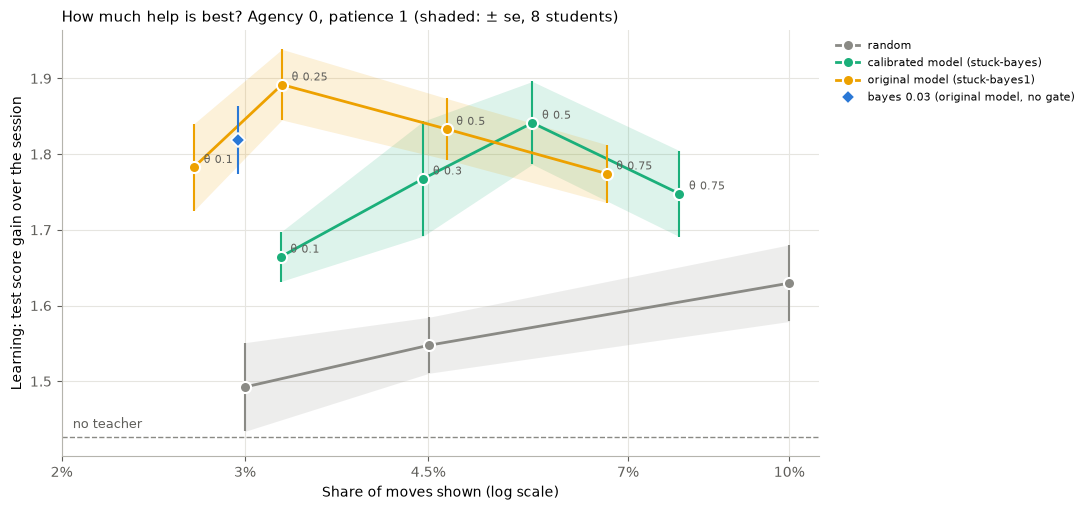

In [8]:
MODELS = {"stuck-bayes": ("calibrated model (stuck-bayes)", "#1baf7a"),
          "stuck-bayes1": ("original model (stuck-bayes1)", "#eda100")}
SWEEP_SPECS = {"stuck-bayes": ["stuck-bayes:0.1", "stuck-bayes:0.3", "stuck-bayes:0.5", "stuck-bayes:0.75"],
               "stuck-bayes1": ["stuck-bayes1:0.1", "stuck-bayes1:0.25", "stuck-bayes1:0.5", "stuck-bayes1:0.75"]}
RANDOM = ["random:0.03", "random:0.045", "random:0.1"]


def spend(e):
    records = [x for record in e["sessions"].values() for x in record]
    return sum(x["taught"] for x in records) / sum(x["moves"] for x in records)


def sweep_table():
    rows = []
    for kind, specs in SWEEP_SPECS.items():
        other = "stuck-bayes" if kind == "stuck-bayes1" else "stuck-bayes1"
        for spec, twin in zip(specs, SWEEP_SPECS[other]):
            e = entry(RUN, spec)
            if e is None:
                continue
            m, s = te.mean_se(learning(e))
            base, partner = entry(RUN, "stuck-bayes:0.3"), entry(RUN, twin)
            rows.append({"teacher": se.teacher_name(spec), "shown": spend(e),
                         "solved as played": np.mean([x["solved"] for r in e["sessions"].values() for x in r]),
                         "learning": f"{m:+.3f} ± {s:.3f}",
                         "vs stuck-bayes 0.3": paired(e, base) if spec != "stuck-bayes:0.3" else "",
                         "vs other model, same theta": f"{se.teacher_name(twin)}: {paired(e, partner)}"
                         if partner is not None else ""})
    return pd.DataFrame(rows).round(3)


def sweep_figure(path):
    """Learning against spend: one line per model (labelled with theta), random's curve, bayes 0.03, no teacher."""
    fig, ax = plt.subplots(figsize=(11, 5.2))
    none = entry(NONE_RUN, "none")
    base = np.mean(learning(none))
    ax.axhline(base, color="#8a8a85", lw=1, ls="--", zorder=0)
    ax.text(0.0205, base + 0.008, "no teacher", color="#5f5e5a", fontsize=9, va="bottom")
    lines = [("random", RANDOM, "#8a8a85")] + [(label, SWEEP_SPECS[k], c) for k, (label, c) in MODELS.items()]
    for label, specs, c in lines:
        pts = [(spend(e), *te.mean_se(learning(e)), spec) for spec in specs if (e := entry(RUN, spec)) is not None]
        if not pts:
            continue
        pts.sort()
        x, m, s = (np.array([p[i] for p in pts]) for i in range(3))
        ax.fill_between(x, m - s, m + s, color=c, alpha=0.15, lw=0)
        ax.errorbar(x, m, yerr=s, fmt="none", ecolor=c, elinewidth=1.5, capsize=0)
        ax.plot(x, m, "-o", color=c, lw=2, ms=8, mec="white", mew=1.5, label=label)
        if label != "random":
            for xx, mm, spec in zip(x, m, [p[3] for p in pts]):
                ax.annotate(f"θ {spec.split(':')[1]}", (xx, mm), xytext=(7, 3), textcoords="offset points",
                            ha="left", fontsize=8, color="#5f5e5a")
    b = entry(RUN, "bayes:0.03")
    if b is not None:
        m, s = te.mean_se(learning(b))
        ax.errorbar(spend(b), m, yerr=s, fmt="D", ms=7, color="#2a78d6", mec="white", mew=1.2, capsize=0,
                    label="bayes 0.03 (original model, no gate)")
    ax.set_xscale("log")
    ax.set_xticks([0.02, 0.03, 0.045, 0.07, 0.1], ["2%", "3%", "4.5%", "7%", "10%"])
    ax.minorticks_off()
    ax.set_xlabel("Share of moves shown (log scale)")
    ax.set_ylabel("Learning: test score gain over the session")
    ax.set_title("How much help is best? Agency 0, patience 1 (shaded: ± se, 8 students)", fontsize=11, loc="left")
    ax.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
    ax.grid(color="#e6e5e0", lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#b5b4ad")
    ax.tick_params(colors="#5f5e5a")
    plt.tight_layout()
    os.makedirs(os.path.dirname(path), exist_ok=True)
    plt.savefig(path, dpi=150)
    plt.show()


display(sweep_table())
sweep_figure(os.path.join(FIGURES, "stuck_bayes_sweep.png"))

### Result: one peak per model, about the same height; the original model needs less help to reach it

| theta | calibrated (stuck-bayes): shown, learning | original (stuck-bayes1): shown, learning |
|---|---|---|
| 0.1 | 3.2%, +1.66 ± 0.03 | 2.7%, +1.78 ± 0.06 |
| 0.25 / 0.3 | 4.5%, +1.77 ± 0.08 | **3.3%, +1.89 ± 0.05** |
| 0.5 | **5.7%, +1.84 ± 0.06** | 4.7%, +1.83 ± 0.04 |
| 0.75 | 7.8%, +1.75 ± 0.06 | 6.7%, +1.77 ± 0.04 |

- **Both curves rise and fall**, as the assistance dilemma predicts, and both stay well above random (+1.49 to +1.63
  at 3-10%) everywhere they were tried.
- **The original model peaks at theta 0.25 (3.3% shown).** Paired with that peak, its own neighbours learn less:
  theta 0.1 by 0.11 ± 0.05 (6/8 students), 0.5 by 0.06 ± 0.06 (6/8), and 0.75 by 0.12 ± 0.07 (6/8). The peak is
  real but broad. Anywhere from about 3% to 5% is within about one standard error of it.
- **The calibrated model peaks at theta 0.5 (5.7% shown)**, 0.05 ± 0.04 below the original's peak (4/8). The two
  peaks are the same height within noise, but the original model gets there with about 40% less help shown.
- **At the same theta the models pick different amounts of help.** The original model's solve-chance estimate sits
  higher, so it shows less. Where their spends overlap (4.5-7%) the curves agree. The original model also extends
  the curve down to 2.7-3.3%, where the calibrated model never goes at these thetas. That low region is where the
  best run so far, stuck-bayes1 0.25, lies.
- **References at the peak:** bayes 0.03 (the original model with no gate, 3%) is 0.07 ± 0.06 below it (5/8).
  The model-free hint 5 p2 is 0.20 ± 0.05 below (8/8), and hint-bayes 0.25 is 0.19 ± 0.05 below (7/8).

**Baseline for the ablations: stuck-bayes1, theta 0.25, patience 1.** Each ablation removes one part of it. Since
removing a part shifts how much help a given theta buys, each one gets two thetas, aimed at the baseline's peak
(about 3.3% shown) and at its theta 0.5 point (about 4.7%). It is then read against the baseline curve: its best
run against the baseline's best, and each run against the baseline at the same spend.

## Ablations: which parts of stuck-bayes1 does it need?

The baseline is stuck-bayes1 at theta 0.25, patience 1: 3.3% shown, +1.89 learning, the best teacher so far. It has
an original-model (Bayesian) picture of the student under a gate. Each ablation removes one part, using a switch on
the teacher (`scripts/teach.py`, StuckGate):

| switch | part removed | what is left |
|---|---|---|
| `patience=0` | the gate | the solve-chance rule alone, from the first move |
| `update=0` | updating this puzzle's difficulty from the student's moves on it | the plan averages over the prior; being stuck is still seen by the gate |
| `refit=100` | following the student's learning | the model of the student (skill per distance, level, tau, mistakes, persistence) learns from the first 100 of 2,160 puzzles, then stays fixed |
| `giveup=0` | the persistence model | no chance of giving up in the plan: only the move cap ends a puzzle |
| `backward=0` | the direction of mistakes | every mistake is sideways: the plan never has the student slide back |

Removing a part changes how much help a given theta buys, so each ablation's thetas came from the mini test (2
students x 80 puzzles). They were aimed at the baseline's mini-test spend at theta 0.25 (4.4%, which is 3.3% in a
full session) and at theta 0.5 (6.4%, which is 4.7%). Mini-test spend at theta 0.25, against the baseline's 4.4%:

| ablation | 0.25 | 0.45 | 0.5 | 0.7 | 0.85 | chosen thetas |
|---|---|---|---|---|---|---|
| no gate | 4.8% | 6.4% | | | | 0.2, 0.45 |
| no update | 2.8% | 4.0% | 4.8% | 5.6% | 10.3% | 0.5, 0.75 |
| frozen (refit 20 as proxy) | 4.8% | | | | | 0.25, 0.5 (as the baseline) |
| no give-up | 3.6% | 4.4% | | 5.8% (0.6) | | 0.45, 0.7 |
| no backward | 2.6% | 2.2% | | 3.0% | 4.9% (12.2% at 0.95) | 0.82, 0.88 |

- With no backward mistakes, the model thinks the student almost always gets there, until the move cap is close. So
  spend hardly moves until theta is above 0.8, and then it climbs steeply.
- Without the gate, the same theta buys about the same help. The model rarely gives the student under 0.25 before
  it is stuck anyway.
- The mini test can't see `refit=100` (it ends at 80 puzzles). `refit=20` shows a bit more help, so the full runs
  use the baseline's thetas.

10 runs, about 22 minutes each (about 3.7 hours). The queue plays every ablation's first theta before any second
one, so a partial queue still covers all five parts.

In [9]:
ABLATIONS = {  # label: (switch, [thetas])
    "no gate": ("patience=0", [0.2, 0.45]),
    "no within-puzzle update": ("update=0", [0.5, 0.75]),
    "frozen after 100 puzzles": ("refit=100", [0.25, 0.5]),
    "no give-up in the plan": ("giveup=0", [0.45, 0.7]),
    "mistakes all sideways": ("backward=0", [0.82, 0.88]),
}
ABLATION_SPECS = {label: [f"stuck-bayes1:{t:g},{switch}" for t in thetas] for label, (switch, thetas) in ABLATIONS.items()}
launch("stuck_bayes_ablations", [specs[i] for i in range(2) for specs in ABLATION_SPECS.values()])

stuck_bayes_ablations: all 10 teacher runs are saved, nothing to play


In [10]:
watch("stuck_bayes_ablations")

stuck_bayes_ablations: 100%|██████████| , finished: 10.0/10 teacher runs in 3m


### Ablation results

The table and figure compare each ablation with the baseline curve (stuck-bayes1 at theta 0.1 / 0.25 / 0.5 / 0.75).
"vs baseline peak" pairs each run with stuck-bayes1 0.25. "vs baseline, nearest spend" pairs it with the baseline
run whose spend is closest. Both are learning differences: above 0 means the ablation learned more. The last panel
puts each ablation's best run against the baseline's best. With 8 students, a difference within about ±0.1 can't be
told apart from no difference.

,ablation,teacher,shown,solved as played,learning,vs baseline peak,"vs baseline, nearest spend"
0,baseline,stuck-bayes1 0.1,0.027,0.804,+1.783 ± 0.057,-0.109 ± 0.049 (2/8),
1,baseline,stuck-bayes1 0.25,0.033,0.836,+1.892 ± 0.047,,
2,baseline,stuck-bayes1 0.5,0.047,0.873,+1.833 ± 0.040,-0.059 ± 0.058 (2/8),
3,baseline,stuck-bayes1 0.75,0.067,0.903,+1.774 ± 0.038,-0.117 ± 0.071 (2/8),
4,no gate,stuck-bayes1 0.2 p0,0.030,0.849,+1.899 ± 0.043,+0.007 ± 0.035 (3/8),stuck-bayes1 0.25: +0.007 ± 0.035 (3/8)
5,no gate,stuck-bayes1 0.45 p0,0.046,0.883,+1.914 ± 0.045,+0.022 ± 0.046 (5/8),stuck-bayes1 0.5: +0.081 ± 0.069 (5/8)
6,no within-puzzle update,stuck-bayes1 0.5 no-update,0.022,0.800,+1.751 ± 0.052,-0.141 ± 0.025 (1/8),stuck-bayes1 0.1: -0.032 ± 0.057 (3/8)
7,no within-puzzle update,stuck-bayes1 0.75 no-update,0.055,0.861,+1.815 ± 0.061,-0.077 ± 0.062 (2/8),stuck-bayes1 0.5: -0.018 ± 0.070 (3/8)
8,frozen after 100 puzzles,stuck-bayes1 0.25 frozen100,0.030,0.828,+1.802 ± 0.051,-0.090 ± 0.057 (3/8),stuck-bayes1 0.25: -0.090 ± 0.057 (3/8)
9,frozen after 100 puzzles,stuck-bayes1 0.5 frozen100,0.042,0.862,+1.851 ± 0.067,-0.041 ± 0.036 (2/8),stuck-bayes1 0.5: +0.018 ± 0.064 (4/8)


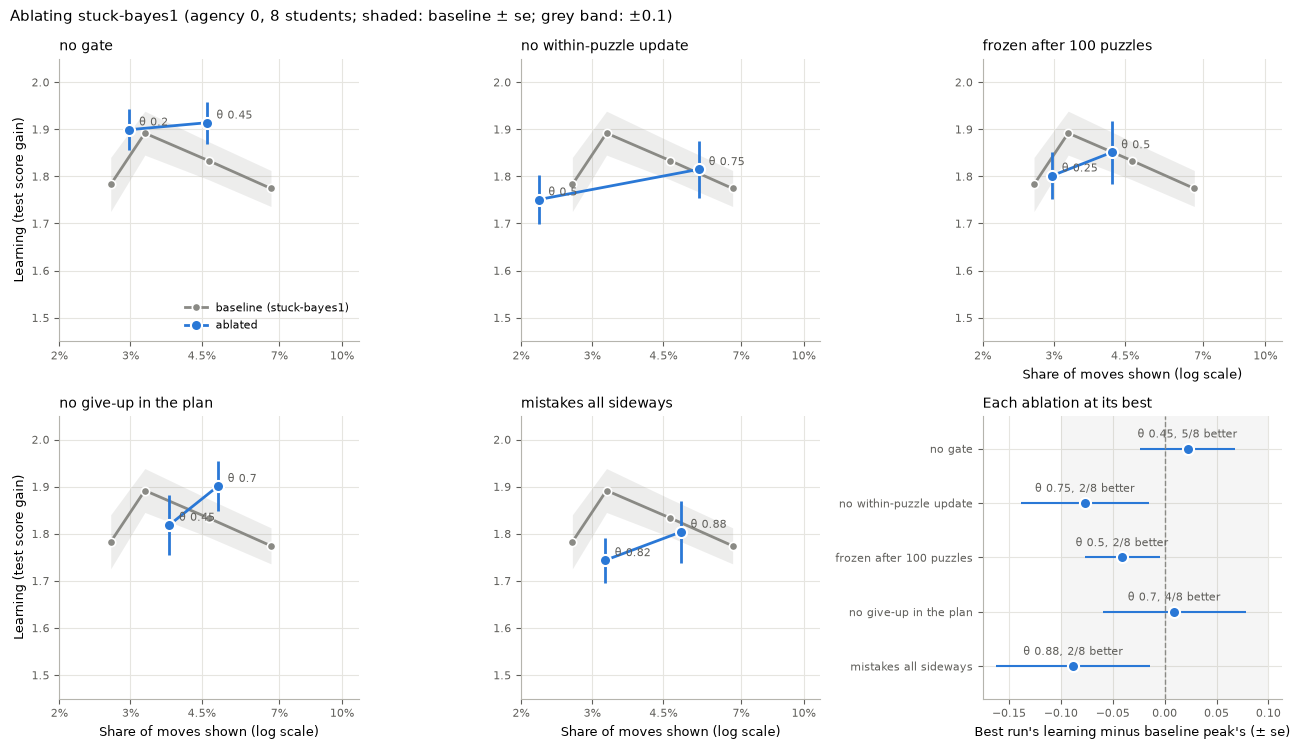

In [11]:
BASELINE = "stuck-bayes1:0.25"
BASELINE_CURVE = ["stuck-bayes1:0.1", "stuck-bayes1:0.25", "stuck-bayes1:0.5", "stuck-bayes1:0.75"]


def learning_gain(e, base):
    """Learning minus `base`'s, student by student (all start from the same network): (mean, se, k better, n)."""
    a, b = dict(zip(final(e), learning(e))), dict(zip(final(base), learning(base)))
    d = [a[s] - b[s] for s in a if s in b]
    return (*te.mean_se(d), sum(x > 0 for x in d), len(d))


def gain_text(e, base):
    m, s, k, n = learning_gain(e, base)
    return f"{m:+.3f} ± {s:.3f} ({k}/{n})"


def ablation_table():
    curve_runs = [(spend(b), spec, b) for spec in BASELINE_CURVE if (b := entry(RUN, spec)) is not None]
    peak = entry(RUN, BASELINE)
    rows = []
    for label, specs in {"baseline": BASELINE_CURVE, **ABLATION_SPECS}.items():
        for spec in specs:
            e = entry(RUN, spec)
            if e is None:
                print(f"{se.teacher_name(spec)}: not saved yet")
                continue
            m, s = te.mean_se(learning(e))
            near = min(curve_runs, key=lambda c: abs(np.log(c[0] / spend(e))))
            rows.append({"ablation": label, "teacher": se.teacher_name(spec), "shown": spend(e),
                         "solved as played": np.mean([x["solved"] for r in e["sessions"].values() for x in r]),
                         "learning": f"{m:+.3f} ± {s:.3f}",
                         "vs baseline peak": gain_text(e, peak) if spec != BASELINE else "",
                         "vs baseline, nearest spend": f"{se.teacher_name(near[1])}: {gain_text(e, near[2])}"
                         if label != "baseline" else ""})
    return pd.DataFrame(rows).round(3)


def _style(ax):
    ax.grid(color="#e6e5e0", lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#b5b4ad")
    ax.tick_params(colors="#5f5e5a", labelsize=8)


def _points(specs):
    pts = sorted((spend(e), *te.mean_se(learning(e)), spec) for spec in specs if (e := entry(RUN, spec)) is not None)
    return [np.array([p[i] for p in pts]) for i in range(3)] + [[p[3] for p in pts]]


def _theta(spec):
    return spec.split(":")[1].split(",")[0]


def ablation_figure(path):
    """One panel per ablation (its runs against the baseline curve), and a last panel: each ablation's best run
    minus the baseline's best, paired by student."""
    n = len(ABLATION_SPECS) + 1  # a panel per ablation, and the summary
    rows_ = -(-n // 3)
    fig, axes = plt.subplots(rows_, 3, figsize=(13, 3.8 * rows_), squeeze=False)
    panels = list(axes.flat)
    bx, bm, bs, _ = _points(BASELINE_CURVE)
    for ax, (label, specs) in zip(panels, ABLATION_SPECS.items()):
        ax.fill_between(bx, bm - bs, bm + bs, color="#8a8a85", alpha=0.15, lw=0)
        ax.plot(bx, bm, "-o", color="#8a8a85", lw=2, ms=6, mec="white", mew=1.2, label="baseline (stuck-bayes1)")
        x, m, s, sp = _points(specs)
        if len(x):
            ax.errorbar(x, m, yerr=s, fmt="-o", color="#2a78d6", lw=2, ms=8, mec="white", mew=1.5, capsize=0,
                        label="ablated")
            for xx, mm, spec in zip(x, m, sp):
                ax.annotate(f"θ {_theta(spec)}", (xx, mm), xytext=(7, 3), textcoords="offset points", fontsize=8,
                            color="#5f5e5a")
        ax.set_xscale("log")
        ax.set_xticks([0.02, 0.03, 0.045, 0.07, 0.1], ["2%", "3%", "4.5%", "7%", "10%"])
        ax.minorticks_off()
        ax.set_xlim(0.02, 0.11)
        ax.set_ylim(1.45, 2.05)
        ax.set_title(label, fontsize=10, loc="left")
        _style(ax)
    panels[0].legend(fontsize=8, frameon=False, loc="lower right")
    for i, ax in enumerate(panels[:n - 1]):
        if i + 3 >= n - 1:  # no ablation panel below it
            ax.set_xlabel("Share of moves shown (log scale)", fontsize=9)
        if i % 3 == 0:
            ax.set_ylabel("Learning (test score gain)", fontsize=9)
    for ax in panels[n:]:
        ax.axis("off")

    ax = panels[n - 1]
    peak, rows = entry(RUN, BASELINE), []
    for label, specs in ABLATION_SPECS.items():
        saved = [(np.mean(learning(e)), spec, e) for spec in specs if (e := entry(RUN, spec)) is not None]
        if saved:
            _, spec, e = max(saved, key=lambda t: t[0])
            rows.append((label, spec, *learning_gain(e, peak)))
    for i, (label, spec, m, s, k, n) in enumerate(rows):
        ax.errorbar(m, i, xerr=s, fmt="o", color="#2a78d6", ms=8, mec="white", mew=1.5, capsize=0)
        ax.annotate(f"θ {_theta(spec)}, {k}/{n} better", (m, i), xytext=(0, 8), textcoords="offset points",
                    ha="center", fontsize=8, color="#5f5e5a")
    ax.axvline(0, color="#8a8a85", lw=1, ls="--")
    ax.axvspan(-0.1, 0.1, color="#8a8a85", alpha=0.08, lw=0)
    ax.set_yticks(range(len(rows)), [r[0] for r in rows], fontsize=8)
    ax.set_ylim(-0.6, max(len(rows), 1) - 0.4)
    ax.invert_yaxis()
    ax.set_xlabel("Best run's learning minus baseline peak's (± se)", fontsize=9)
    ax.set_title("Each ablation at its best", fontsize=10, loc="left")
    _style(ax)
    fig.suptitle("Ablating stuck-bayes1 (agency 0, 8 students; shaded: baseline ± se; grey band: ±0.1)",
                 fontsize=11, x=0.01, ha="left")
    plt.tight_layout()
    os.makedirs(os.path.dirname(path), exist_ok=True)
    plt.savefig(path, dpi=150)
    plt.show()


display(ablation_table())
ablation_figure(os.path.join(FIGURES, "stuck_bayes_ablations.png"))

### Result: the gate and the give-up model can go; backward mistakes stay; the rest is unclear at 8 students

Each ablation's learning minus the baseline's, paired by student (above 0: the ablation learned more):

| ablation | run (shown) | vs baseline peak (θ 0.25, 3.3%) | vs baseline at nearest spend |
|---|---|---|---|
| no gate | θ 0.2 (3.0%) | +0.01 ± 0.04 (3/8) | same |
| | θ 0.45 (4.6%) | **+0.02 ± 0.05 (5/8)** | +0.08 ± 0.07 vs θ 0.5 |
| no give-up in the plan | θ 0.45 (3.7%) | −0.07 ± 0.07 (3/8) | same |
| | θ 0.7 (4.9%) | **+0.01 ± 0.07 (4/8)** | +0.07 ± 0.09 vs θ 0.5 |
| frozen after 100 puzzles | θ 0.25 (3.0%) | −0.09 ± 0.06 (3/8) | same |
| | θ 0.5 (4.2%) | **−0.04 ± 0.04 (2/8)** | +0.02 ± 0.06 vs θ 0.5 |
| no within-puzzle update | θ 0.5 (2.2%) | −0.14 ± 0.03 (1/8) | −0.03 ± 0.06 vs θ 0.1 |
| | θ 0.75 (5.5%) | **−0.08 ± 0.06 (2/8)** | −0.02 ± 0.07 vs θ 0.5 |
| mistakes all sideways | θ 0.82 (3.2%) | −0.15 ± 0.07 (2/8) | same |
| | θ 0.88 (5.0%) | **−0.09 ± 0.07 (2/8)** | −0.03 ± 0.09 vs θ 0.5 |

- **No gate: not needed.** Both runs match the baseline's peak. At 4.6% the curve without the gate is flatter than
  the baseline's (+1.91 against +1.83 at θ 0.5). A likely reason: early in a puzzle the solve chance is rarely
  below theta until the student's own moves have lowered it, so the rule holds back on its own and patience adds
  nothing.
- **No give-up in the plan: not needed.** θ 0.7 (4.9%) ties the peak. With only the move cap ending a puzzle, the
  model is more optimistic, so it takes a higher theta for the same help, and a higher theta is all it needs.
- **Mistakes all sideways: a loss.** At the baseline's own spend (3.2%) it learns 0.15 ± 0.07 less (6/8 students
  worse). It is the clearest loss here. Without backward mistakes the model sees no difference between a student
  who slides back and one who stalls, so its solve chance stays near 1 until the move cap is close (in the mini test its
  spend barely moved until theta passed 0.8).
- **Frozen after 100 puzzles: probably a small loss.** At its best it is 0.04 ± 0.04 below (6/8 worse). At the same
  spend it is between −0.09 and +0.02. Following the student's learning seems worth a little, but 8 students can't
  pin that down.
- **No within-puzzle update: unclear.** Its spend landed at 2.2% and 5.5%, missing the peak region (3-4%). Against
  the baseline at the nearest spend it is level (−0.02 to −0.03). Against the peak it is 0.08 below at best. It
  needs a run near 3.3% (theta about 0.6).

**Caveat:** the baseline peak is the best of four runs, so part of its lead over any single run is luck: pick the
best of four noisy runs and you pick some noise. The "nearest spend" column avoids that, and there only the
sideways-mistakes run at matched spend loses clearly.

**So far the most parsimonious candidate is the original model's solve-chance rule with no gate and no give-up
model,** keeping backward mistakes. Following the student's learning and within-puzzle updating stay until tested
better. Next: run that combination (removals can interact) and no-update near 3.3%. Then confirm the candidate
against the baseline with more students (16-24), since a difference under about 0.1 can't be resolved at 8.

## Follow-up: the combined candidate, and no-update at the peak

The single ablations left two gaps:

1. **The combination has never been run.** Dropping the gate is fine, and dropping the give-up model is fine, each on
   its own. Removals can interact, though: without the gate, only the solve-chance estimate holds help back early in a
   puzzle, and the give-up model feeds that estimate. So the candidate, stuck-bayes1 with `patience=0, giveup=0`, gets
   its own runs.
2. **No-update's spend missed the peak region.** It landed at 2.2% and 5.5%, against targets of 3.3% and 4.7%.
   Interpolating its two runs on a log scale puts 3.3% at about theta 0.6, so it gets theta 0.6 and 0.65.

Mini-test spend for the combination (2 students x 80 puzzles; noisy) was 3.9% at theta 0.35, 4.7% at 0.5, 7.8% at
0.65 and 7.1% at 0.8. Without the gate alone, mini spend runs about 1.4 times full-session spend, so theta 0.45 and 0.6
aim at about 3.3% and 4.7%. 4 runs, about 1.5 hours.

In [12]:
ABLATION_SPECS["no gate + no give-up"] = [f"stuck-bayes1:{t:g},patience=0,giveup=0" for t in (0.45, 0.6)]
NO_UPDATE_FILL = ["stuck-bayes1:0.6,update=0", "stuck-bayes1:0.65,update=0"]
ABLATION_SPECS["no within-puzzle update"] += NO_UPDATE_FILL
launch("stuck_bayes_ablations2", ["stuck-bayes1:0.45,patience=0,giveup=0", NO_UPDATE_FILL[0],
                                  "stuck-bayes1:0.6,patience=0,giveup=0", NO_UPDATE_FILL[1]])

stuck_bayes_ablations2: all 4 teacher runs are saved, nothing to play


In [13]:
watch("stuck_bayes_ablations2")

stuck_bayes_ablations2: 100%|██████████| , finished: 4.0/4 teacher runs in 1h31m


,ablation,teacher,shown,solved as played,learning,vs baseline peak,"vs baseline, nearest spend"
0,baseline,stuck-bayes1 0.1,0.027,0.804,+1.783 ± 0.057,-0.109 ± 0.049 (2/8),
1,baseline,stuck-bayes1 0.25,0.033,0.836,+1.892 ± 0.047,,
2,baseline,stuck-bayes1 0.5,0.047,0.873,+1.833 ± 0.040,-0.059 ± 0.058 (2/8),
3,baseline,stuck-bayes1 0.75,0.067,0.903,+1.774 ± 0.038,-0.117 ± 0.071 (2/8),
4,no gate,stuck-bayes1 0.2 p0,0.030,0.849,+1.899 ± 0.043,+0.007 ± 0.035 (3/8),stuck-bayes1 0.25: +0.007 ± 0.035 (3/8)
5,no gate,stuck-bayes1 0.45 p0,0.046,0.883,+1.914 ± 0.045,+0.022 ± 0.046 (5/8),stuck-bayes1 0.5: +0.081 ± 0.069 (5/8)
6,no within-puzzle update,stuck-bayes1 0.5 no-update,0.022,0.800,+1.751 ± 0.052,-0.141 ± 0.025 (1/8),stuck-bayes1 0.1: -0.032 ± 0.057 (3/8)
7,no within-puzzle update,stuck-bayes1 0.75 no-update,0.055,0.861,+1.815 ± 0.061,-0.077 ± 0.062 (2/8),stuck-bayes1 0.5: -0.018 ± 0.070 (3/8)
8,no within-puzzle update,stuck-bayes1 0.6 no-update,0.028,0.819,+1.793 ± 0.044,-0.098 ± 0.063 (3/8),stuck-bayes1 0.1: +0.011 ± 0.044 (5/8)
9,no within-puzzle update,stuck-bayes1 0.65 no-update,0.034,0.828,+1.769 ± 0.039,-0.123 ± 0.046 (1/8),stuck-bayes1 0.25: -0.123 ± 0.046 (1/8)


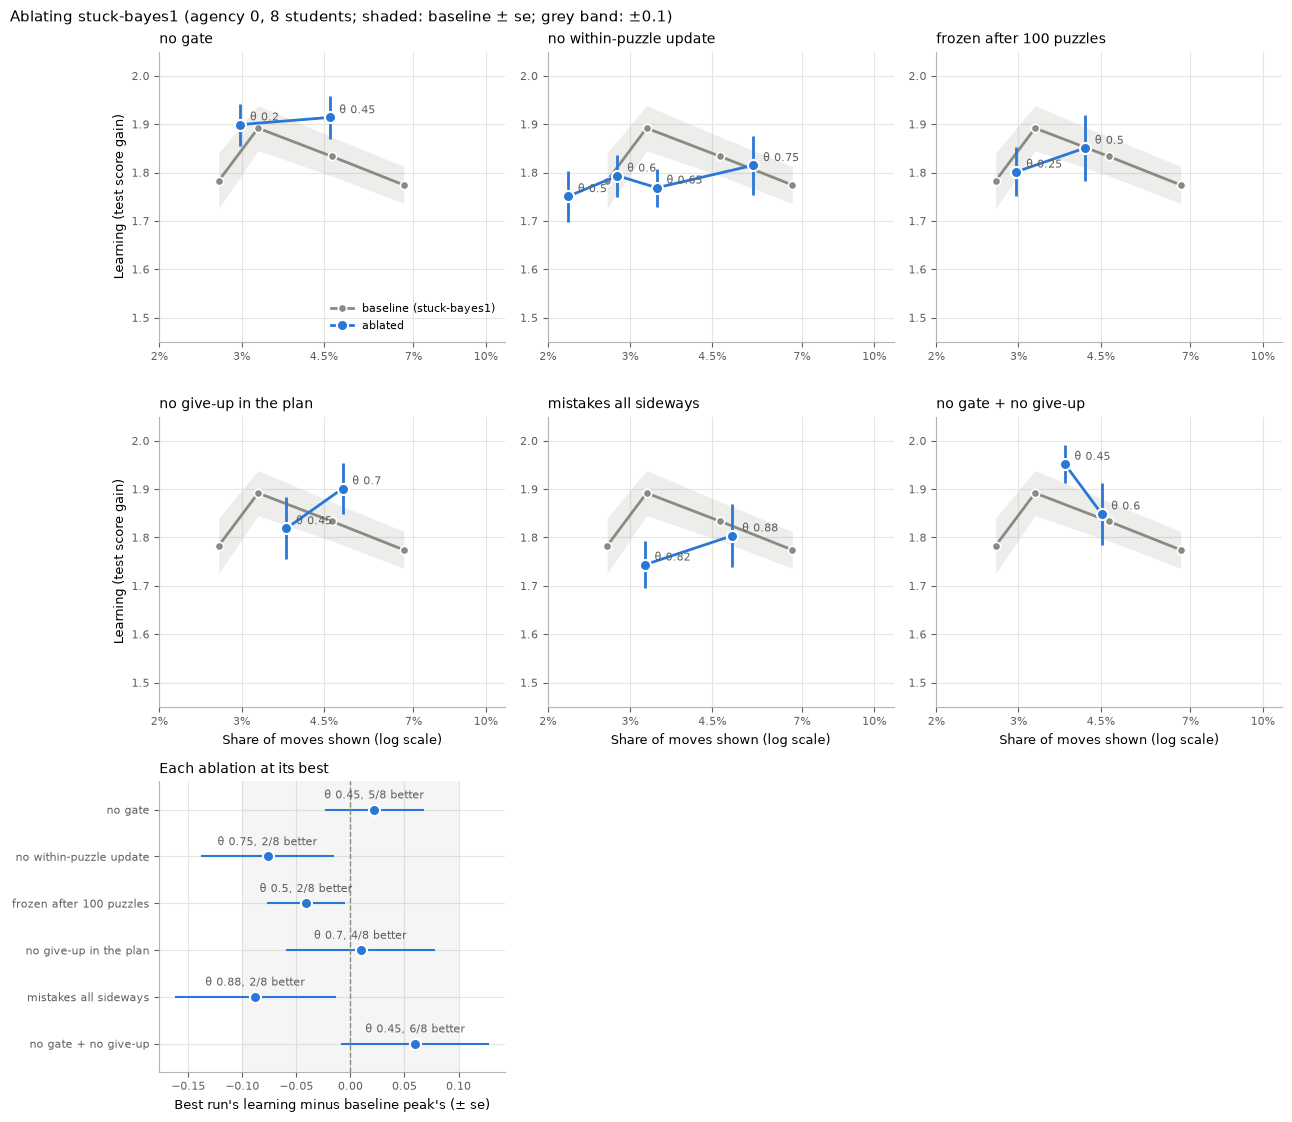

In [14]:
display(ablation_table())
ablation_figure(os.path.join(FIGURES, "stuck_bayes_ablations.png"))

### Follow-up result: the combination holds up; the within-puzzle update is needed

Learning minus the baseline peak's (stuck-bayes1 0.25: 3.3%, +1.89), paired by student:

| teacher | shown | learning | vs baseline peak |
|---|---|---|---|
| no gate + no give-up, θ 0.45 | 3.8% | **+1.95 ± 0.04** | +0.06 ± 0.07 (6/8 better) |
| no gate + no give-up, θ 0.6 | 4.5% | +1.85 ± 0.06 | −0.04 ± 0.08 (3/8); +0.02 ± 0.07 vs baseline θ 0.5 |
| no update, θ 0.6 | 2.8% | +1.79 ± 0.04 | −0.10 ± 0.06 (3/8) |
| no update, θ 0.65 | 3.4% | +1.77 ± 0.04 | −0.12 ± 0.05 (1/8) at matched spend |

- **The combination is fine.** At θ 0.45 it has the highest learning of any teacher so far (+1.95). That is level with or a little
  above the baseline peak (+0.06 ± 0.07, 6/8 students), and level with dropping either part alone (+0.04 ± 0.04 vs no gate θ
  0.45; +0.05 ± 0.04 vs no give-up θ 0.7). Dropping both parts costs nothing.
- **The within-puzzle update is needed.** At the baseline's own spend (3.4%) no-update learns 0.12 ± 0.05 less, with 7 of
  8 students worse. Its four runs (2.2% to 5.5%) are flat at +1.75 to +1.82 and never reach the baseline's peak. It is
  what tells the teacher, while a puzzle is under way, that this student is struggling on it.
- **Against the original Bayesian teacher** (bayes 0.03: the same model of the student, but a cost-benefit rule with a
  spending target), the combination at θ 0.45 learns 0.13 ± 0.04 more (6/8). So, on the same model, a plain
  solve-chance threshold beats that rule.

**The most parsimonious teacher so far:** the original Bayesian model of the student, with skill per distance to the
goal followed over the session, a per-puzzle difficulty updated by the student's own moves, and backward as well as
sideways mistakes. It shows the optimal move whenever the model's chance that the student solves alone is under θ
(about 0.45, for about 4% of moves shown). There is no gate, no patience and no give-up model.

| part | verdict | evidence (8 students) |
|---|---|---|
| gate / patience | drop | ties the peak alone and combined |
| give-up model | drop | ties the peak alone and combined |
| within-puzzle difficulty update | keep | −0.12 ± 0.05 at matched spend, 7/8 worse |
| backward mistakes | keep | −0.15 ± 0.07 at matched spend, 6/8 worse |
| following the student's learning | keep for now | −0.04 to −0.09 near the peak; not resolved |

**Caveats:** every "best" run here is the best of 2 to 4 noisy runs, so its lead is partly luck. The candidate's
+1.95 should be confirmed with fresh runs and more students (16-24), against the baseline at θ 0.25, before it counts
as better rather than equal.

## Confirmation: the candidate against the baseline, with fresh students

The ablations picked a candidate, stuck-bayes1 with no gate and no give-up model at theta 0.45 (+1.95). Its lead over
the baseline (+0.06 ± 0.07) is too small for 8 students, and partly luck: it is the best of two runs. This
run settles it with fresh data:

- **24 students and seed 1:** new students, new session puzzles and a new test set, none of which were used to pick
  the candidate or its theta. The settings are otherwise the same as the agency-0 run.
- **Two teachers at their chosen thetas:** the baseline (stuck-bayes1 0.25) and the candidate
  (`stuck-bayes1:0.45,patience=0,giveup=0`). Nothing is re-tuned, so this tests the choice as it was made.
- **Read as a paired comparison:** each student's learning under the candidate minus under the baseline. With 24
  students the standard error should be about 0.03, so a difference of about 0.06 or more would show. A
  smaller difference means the two are equal, and the simpler teacher wins on parsimony.

With 16 cores, each teacher takes about 45-60 minutes (24 students in about two rounds of parallel sessions), so
about 2 hours in all.

In [15]:
CONFIRM_RUN = "teach_shortcut_agency0_confirm"
CONFIRM_SETTINGS = {**SETTINGS, "students": 24, "seed": 1}
CANDIDATE = "stuck-bayes1:0.45,patience=0,giveup=0"
CONFIRM = [CANDIDATE, BASELINE]
launch("stuck_bayes_confirm", CONFIRM, run=CONFIRM_RUN, settings=CONFIRM_SETTINGS)

stuck_bayes_confirm: all 2 teacher runs are saved, nothing to play


In [16]:
watch("stuck_bayes_confirm")

stuck_bayes_confirm: 100%|██████████| , finished: 2.0/2 teacher runs in 1h05m


### Confirmation results

The table gives each teacher's spend and learning in the fresh run, and the candidate minus the baseline, paired by
student. The figure shows each student's learning under both teachers, one line per student. A line rising to the
right means that student learned more with the candidate.

,teacher,shown,solved as played,learning,"vs baseline (learning, paired)"
0,stuck-bayes1 0.45 p0 no-giveup,0.037,0.874,+1.792 ± 0.031,+0.068 ± 0.046 (15/24)
1,stuck-bayes1 0.25,0.033,0.837,+1.724 ± 0.039,


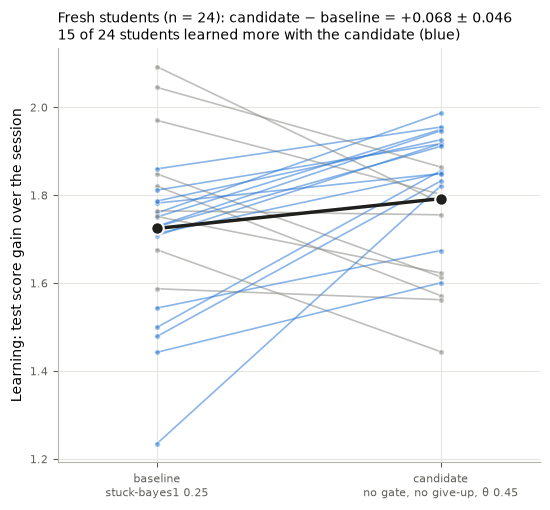

In [17]:
def confirm_table():
    rows = []
    base = entry(CONFIRM_RUN, BASELINE)
    for spec in CONFIRM:
        e = entry(CONFIRM_RUN, spec)
        if e is None:
            print(f"{se.teacher_name(spec)}: not saved yet")
            continue
        m, s = te.mean_se(learning(e))
        rows.append({"teacher": se.teacher_name(spec), "shown": spend(e),
                     "solved as played": np.mean([x["solved"] for r in e["sessions"].values() for x in r]),
                     "learning": f"{m:+.3f} ± {s:.3f}",
                     "vs baseline (learning, paired)": gain_text(e, base) if spec != BASELINE and base else ""})
    return pd.DataFrame(rows).round(3)


def confirm_figure(path):
    """Each student's learning under the baseline and the candidate (one line per student), with the means."""
    base, cand = entry(CONFIRM_RUN, BASELINE), entry(CONFIRM_RUN, CANDIDATE)
    if base is None or cand is None:
        print("waiting for both teachers")
        return
    a, b = dict(zip(final(base), learning(base))), dict(zip(final(cand), learning(cand)))
    students = [s for s in a if s in b]
    fig, ax = plt.subplots(figsize=(5.6, 5.2))
    for s in students:
        up = b[s] > a[s]
        ax.plot([0, 1], [a[s], b[s]], "-o", color="#2a78d6" if up else "#8a8a85", alpha=0.55, lw=1.2, ms=4,
                mec="white", mew=0.8)
    ma, mb = np.mean([a[s] for s in students]), np.mean([b[s] for s in students])
    ax.plot([0, 1], [ma, mb], "-o", color="#1f1f1d", lw=2.5, ms=9, mec="white", mew=1.5)
    m, se_, k, n = learning_gain(cand, base)
    ax.set_xticks([0, 1], [f"baseline\n{se.teacher_name(BASELINE)}", "candidate\nno gate, no give-up, θ 0.45"],
                  fontsize=9)
    ax.set_xlim(-0.35, 1.35)
    ax.set_ylabel("Learning: test score gain over the session")
    ax.set_title(f"Fresh students (n = {n}): candidate − baseline = {m:+.3f} ± {se_:.3f}\n"
                 f"{k} of {n} students learned more with the candidate (blue)", fontsize=10, loc="left")
    _style(ax)
    plt.tight_layout()
    os.makedirs(os.path.dirname(path), exist_ok=True)
    plt.savefig(path, dpi=150)
    plt.show()


display(confirm_table())
confirm_figure(os.path.join(FIGURES, "stuck_bayes_confirm.png"))

### Confirmation result: the simpler teacher is at least as good, and probably a little better

| teacher (24 fresh students) | shown | solved as played | learning |
|---|---|---|---|
| candidate: no gate, no give-up, θ 0.45 | 3.7% | 0.87 | **+1.79 ± 0.03** |
| baseline: stuck-bayes1 0.25 | 3.3% | 0.84 | +1.72 ± 0.04 |

- **The candidate minus the baseline is +0.07 ± 0.05,** with 15 of 24 students better (median +0.12; t-test p = 0.15).
  Pooled with the 8 students of the ablation run, it is +0.07 ± 0.04 (21 of 32 better, p = 0.09). The 95% interval
  runs from −0.01 to +0.14.
- **The candidate leads at every test along the session,** not only at the end: the test score was 4.41 against 4.50
  after 540 puzzles, 4.06 against 4.11 after 1,080, 3.83 against 3.96 after 1,620, and 3.69 against 3.76 at the end
  (lower is better).
- **The difference between students is larger than planned for.** The per-student sd of the paired difference is
  0.22, not the roughly 0.15 assumed when planning this run, so the standard error is 0.05, not 0.03. To detect a
  0.07 difference reliably (80% power) would take about 80 students. That isn't worth it here: the question was
  whether the simpler teacher loses anything, and it doesn't. At worst it is 0.01 behind; most likely it is a
  little ahead.
- **Both teachers learn less here than in the ablation run** (+1.72 against +1.89 for the baseline), because the
  students, session puzzles and test set are all new. Only the comparison within the run counts.
- The candidate shows a bit more help (3.7% against 3.3%). It helps on more puzzles (19% against 17%), and the
  student makes fewer moves of its own on them (128 against 152 on helped puzzles). Without the gate it steps in
  sooner, and on more puzzles.

**Conclusion of the ablations:** the most parsimonious teacher so far is the original Bayesian model of the student
with a plain threshold rule. It shows the optimal move whenever the model's chance that the student solves alone,
from here, is under 0.45. The model of the student keeps:
- skill per distance to the goal, followed over the session;
- a per-puzzle difficulty updated by the student's own moves;
- backward as well as sideways mistakes.

Gone are the gate (patience), the give-up model, the calibration (distance from the start, as in stuck-bayes), and
the cost-benefit rule with its spending target. The rule it uses beats that cost-benefit rule (bayes 0.03) by 0.13
± 0.04 on the same model.

Still open: following the student's learning over the session (frozen after 100 puzzles looked like a small loss,
but wasn't resolved), and the exact theta (0.45 was chosen from two runs; the curve is broad).

## Where is the peak? One curve fitted to every run of the family

So far "the best theta" has been the best single run, which is biased upward (the best of a few noisy runs is
partly luck) and ignores what the other runs say. Here the amount of help is read off a curve fitted to all of them.

- **Which runs:** the ablations found that, at the same amount of help, the gate and the give-up model make no
  difference. So every run of the original model's solve-chance rule that keeps the within-puzzle update and
  backward mistakes is treated as one family: stuck-bayes1 at θ 0.1-0.75 (gated), without the gate, without the
  give-up model, and both removed (bayes3). That is 10 runs on the same 8 students (agency 0), from 2.7% to 6.7% shown.
  Frozen, no-update and no-backward are left out, since they are different models.
- **The model:** each student's learning = that student's own level + a quadratic in log(share of moves shown).
  The student term makes it a paired comparison, as elsewhere in this notebook.
- **Uncertainty:** students are resampled with replacement (4,000 times) and the curve refitted. The 2.5th and 97.5th
  percentiles of the peak's location give its 95% interval, and the band around the curve comes the same way.

peak: 3.99% shown (95% interval 2.92% to 4.57%; concave in 99% of resamples)
learning lost at 0.6 x the peak's share: -0.119
learning lost at 0.75 x the peak's share: -0.038
learning lost at 1.33 x the peak's share: -0.037
learning lost at 1.67 x the peak's share: -0.120


,teacher,variant,shown,learning,on the curve,above the curve
0,stuck-bayes1 0.1,gate,0.027,1.783,1.820,-0.037
4,stuck-bayes1 0.2 p0,no gate,0.030,1.899,1.853,0.046
1,stuck-bayes1 0.25,gate,0.033,1.892,1.873,0.018
6,stuck-bayes1 0.45 no-giveup,no give-up,0.037,1.819,1.890,-0.071
8,stuck-bayes1 0.45 p0 no-giveup,bayes3,0.038,1.952,1.891,0.061
9,stuck-bayes1 0.6 p0 no-giveup,bayes3,0.045,1.849,1.885,-0.036
5,stuck-bayes1 0.45 p0,no gate,0.046,1.914,1.882,0.032
2,stuck-bayes1 0.5,gate,0.047,1.833,1.880,-0.047
7,stuck-bayes1 0.7 no-giveup,no give-up,0.049,1.901,1.871,0.030
3,stuck-bayes1 0.75,gate,0.067,1.774,1.770,0.004


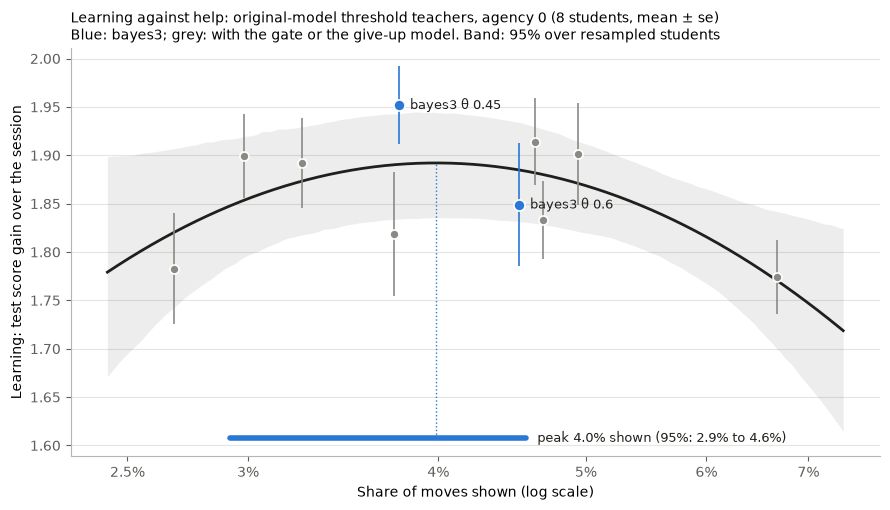

In [18]:
FAMILY = {  # the original model's threshold rule, with the update and backward mistakes; spec: variant
    "stuck-bayes1:0.1": "gate", "stuck-bayes1:0.25": "gate", "stuck-bayes1:0.5": "gate", "stuck-bayes1:0.75": "gate",
    "stuck-bayes1:0.2,patience=0": "no gate", "stuck-bayes1:0.45,patience=0": "no gate",
    "stuck-bayes1:0.45,giveup=0": "no give-up", "stuck-bayes1:0.7,giveup=0": "no give-up",
    "stuck-bayes1:0.45,patience=0,giveup=0": "bayes3", "stuck-bayes1:0.6,patience=0,giveup=0": "bayes3"}


def gains(e):
    """{student: test score gain over the session}."""
    start = measures(e["results"][0][0], e["config"])[0]
    return {s: start - v[0] for s, v in final(e).items()}


def fit_curve(Y, x):
    """Least squares Y[run, student] = a_student + b (x - x0) + c (x - x0)^2, x = log share shown, x0 its mean."""
    R, S = Y.shape
    x0 = x.mean()
    A = np.zeros((R * S, S + 2))
    A[np.arange(R * S), np.tile(np.arange(S), R)] = 1
    A[:, S] = np.repeat(x - x0, S)
    A[:, S + 1] = np.repeat((x - x0) ** 2, S)
    beta = np.linalg.lstsq(A, Y.ravel(), rcond=None)[0]
    return beta[:S].mean(), beta[S], beta[S + 1], x0


def peak_fit(specs=FAMILY, run=RUN, boots=4000, seed=0):
    runs = [(spec, e) for spec in specs if (e := entry(run, spec)) is not None]
    students = sorted(gains(runs[0][1]))
    x = np.array([np.log(spend(e)) for _, e in runs])
    Y = np.array([[gains(e)[s] for s in students] for _, e in runs])
    a, b, c, x0 = fit_curve(Y, x)
    grid = np.linspace(x.min() - 0.1, x.max() + 0.1, 200)
    rng = np.random.default_rng(seed)
    peaks, band = [], []
    for _ in range(boots):
        idx = rng.integers(0, len(students), len(students))
        ab, bb, cb, _ = fit_curve(Y[:, idx], x)
        band.append(ab + bb * (grid - x0) + cb * (grid - x0) ** 2)
        peaks.append(x0 - bb / (2 * cb) if cb < 0 else np.nan)
    peaks = np.array(peaks)
    return {"runs": runs, "x": x, "Y": Y, "a": a, "b": b, "c": c, "x0": x0, "grid": grid,
            "curve": a + b * (grid - x0) + c * (grid - x0) ** 2, "band": np.percentile(band, [2.5, 97.5], axis=0),
            "peak": x0 - b / (2 * c), "peak_ci": np.nanpercentile(peaks, [2.5, 97.5]),
            "concave": np.mean(~np.isnan(peaks))}


def peak_table(f):
    rows = []
    for (spec, e), xr, yr in zip(f["runs"], f["x"], f["Y"]):
        fitted = f["a"] + f["b"] * (xr - f["x0"]) + f["c"] * (xr - f["x0"]) ** 2
        rows.append({"teacher": se.teacher_name(spec), "variant": FAMILY[spec], "shown": np.exp(xr),
                     "learning": yr.mean(), "on the curve": fitted, "above the curve": yr.mean() - fitted})
    return pd.DataFrame(rows).sort_values("shown").round(3)


def peak_figure(f, path):
    fig, ax = plt.subplots(figsize=(9, 5.2))
    g = np.exp(f["grid"])
    ax.fill_between(g, *f["band"], color="#1f1f1d", alpha=0.08, lw=0)
    ax.plot(g, f["curve"], color="#1f1f1d", lw=2, zorder=2)
    for (spec, e), xr, yr in zip(f["runs"], f["x"], f["Y"]):
        m, s = te.mean_se(list(yr))
        blue = FAMILY[spec] == "bayes3"
        c = "#2a78d6" if blue else "#8a8a85"
        ax.errorbar(np.exp(xr), m, yerr=s, fmt="o", color=c, ms=8 if blue else 6.5, mec="white", mew=1.2,
                    elinewidth=1.2, capsize=0, zorder=3)
        if blue:
            ax.annotate(f"bayes3 θ {spec.split(':')[1].split(',')[0]}", (np.exp(xr), m), xytext=(8, 0),
                        textcoords="offset points", fontsize=9, color="#1f1f1d", va="center")
    lo, hi = np.exp(f["peak_ci"])
    py = f["a"] + f["b"] * (f["peak"] - f["x0"]) + f["c"] * (f["peak"] - f["x0"]) ** 2
    y0 = ax.get_ylim()[0]
    ax.plot([lo, hi], [y0 + 0.012] * 2, color="#2a78d6", lw=4, solid_capstyle="round")
    ax.plot([np.exp(f["peak"])] * 2, [y0 + 0.012, py], color="#2a78d6", lw=1, ls=":")
    ax.annotate(f"peak {np.exp(f['peak']):.1%} shown (95%: {lo:.1%} to {hi:.1%})", (hi, y0 + 0.012),
                xytext=(8, 0), textcoords="offset points", fontsize=9, color="#1f1f1d", va="center")
    ax.set_xscale("log")
    ax.set_xticks([0.025, 0.03, 0.04, 0.05, 0.06, 0.07], ["2.5%", "3%", "4%", "5%", "6%", "7%"])
    ax.minorticks_off()
    ax.set_xlabel("Share of moves shown (log scale)")
    ax.set_ylabel("Learning: test score gain over the session")
    ax.set_title("Learning against help: original-model threshold teachers, agency 0 (8 students, mean ± se)\n"
                 "Blue: bayes3; grey: with the gate or the give-up model. Band: 95% over resampled students",
                 fontsize=10, loc="left")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#b5b4ad")
    ax.tick_params(colors="#5f5e5a")
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    ax.set_axisbelow(True)
    plt.tight_layout()
    os.makedirs(os.path.dirname(path), exist_ok=True)
    plt.savefig(path, dpi=150)
    plt.show()


PEAK = peak_fit()
print(f"peak: {np.exp(PEAK['peak']):.2%} shown (95% interval {np.exp(PEAK['peak_ci'][0]):.2%} to "
      f"{np.exp(PEAK['peak_ci'][1]):.2%}; concave in {PEAK['concave']:.0%} of resamples)")
for factor in (0.6, 0.75, 1.33, 1.67):
    print(f"learning lost at {factor:g} x the peak's share: {PEAK['c'] * np.log(factor) ** 2:+.3f}")
display(peak_table(PEAK))
peak_figure(PEAK, os.path.join(FIGURES, "stuck_bayes_peak.png"))

### Result: the peak is at about 4% of moves shown, and it is flat; θ 0.45 is inside it

- **The peak is at 4.0% of moves shown, with a 95% interval of 2.9% to 4.6%.** The curve bends down in 99% of the
  resamples, so the rise and fall is real. Learning at the peak is +1.89.
- **It is flat.** Within a quarter either way of the peak's help (3% to 5.3% shown), the fitted loss is under 0.04. That
  is smaller than the standard error of one run. At 0.6x or 1.67x the peak's help (2.4% or 6.7%) the loss is about 0.12.
- **For bayes3 that means θ of about 0.5.** Its two runs showed 3.8% at θ 0.45 and 4.5% at θ 0.6, and interpolating
  puts 4.0% at θ ≈ 0.5. The interval runs from about θ 0.25 to 0.6, but its lower end is an extrapolation from these
  two runs. θ 0.45 (3.7-3.8% shown, here and in the 24-student confirmation run) is well inside the peak region,
  0.01 below the fitted maximum.
- **bayes3 θ 0.45's +1.95 is 0.06 above the curve.** The runs scatter around the curve by ±0.07, and its point is
  the highest of 10 runs, so most of its lead over the curve is probably luck. That fits the confirmation run, where its
  lead over the gated baseline shrank to 0.07 ± 0.05.
- **The variants sit on one curve.** Their mean distances from it are −0.02 for the gated runs, +0.04 without the gate,
  −0.02 without the give-up model and +0.01 for bayes3. All are within noise, which supports pooling them.

**Caveats:** the interval resamples students only, so it takes the quadratic shape (in log share) as given. The
shape is pinned on the high side by a single run at 6.7%, and the variants are assumed to share one curve. 8
students, one agency.

**For θ:** at agency 0 the exact value hardly matters between 0.45 and 0.5. Moving bayes3's default to 0.5 would
put it at the fitted peak, but the expected gain (about 0.01) is far below what can be measured. Keeping 0.45 also
keeps it equal to the teacher the confirmation run tested. **For the agency sweep,** the same fit per agency (3-4
thetas spanning about 0.6x to 1.7x the expected peak) locates each agency's peak and how flat it is, without needing
the best single run.

## Agency 1: is there still a dilemma, and where does bayes3 sit?

All the runs so far are at agency 0-0.3, chosen to make the assistance dilemma visible. There is no evidence that
people's agency is that low: the generation effect is moderate, and for novices worked examples often teach as much as
solving. Agency 1 was left out of the sweep because "help has no cost there". That rested on the first pilot, where
Adam cancelled the agency weight, so it was never measured with the current setup (skipped steps, shortcut labels).

**Agency 1** means a shown move teaches exactly what a move of the student's own does. Skipped steps never trigger, and
shown moves are optimal labels, better than the student's own. The prediction is that learning rises with help all the
way to full help, so the dilemma is gone. The run has the agency runs' settings with `shown_weight` 1, and
the same 8 students, session puzzles and tests (seed 0). No teacher comes from the agency-0.3 run as before, since
without help agency changes nothing.

| teacher | why |
|---|---|
| random 100% | the test of the dilemma: at agency 0 it learned nothing; at 0.3, +1.11 |
| bayes3 θ 0.45 | the default teacher, the same spec as at agency 0 |
| random 10% | random's peak at agency 0-0.3 |
| bayes3 θ 0.75 and 0.9 | more help from the same teacher, for its curve at this agency |
| random 30% | the middle of random's curve |

The queue runs them in that order, so a partial queue still answers the main question. About 25 minutes each on
the PC, so about 2.5 hours.

In [19]:
AGENCY1_RUN = "teach_shortcut_agency1"
AGENCY1_SETTINGS = {**SETTINGS, "shown_weight": 1.0}
AGENCY1 = ["random:1.0", "bayes3:0.45", "random:0.1", "bayes3:0.75", "bayes3:0.9", "random:0.3"]
launch("agency1", AGENCY1, run=AGENCY1_RUN, settings=AGENCY1_SETTINGS)

agency1 is already running (pid 20728)


In [20]:
watch("agency1")

agency1: 100%|██████████| , finished: 6.0/6 teacher runs in 2h20m                                                                   


,teacher,shown,solved as played,examples per puzzle,learning,vs no teacher,vs random 10%,vs random 30%
1,bayes3 0.45,0.035,0.877,38.889,+2.135 ± 0.048,+0.709 ± 0.088 (8/8),+0.248 ± 0.066 (8/8),+0.089 ± 0.068 (6/8)
3,bayes3 0.75,0.053,0.899,37.749,+2.153 ± 0.079,+0.727 ± 0.122 (8/8),+0.266 ± 0.079 (7/8),+0.106 ± 0.087 (5/8)
4,bayes3 0.9,0.091,0.923,34.616,+2.147 ± 0.024,+0.721 ± 0.057 (8/8),+0.261 ± 0.067 (8/8),+0.101 ± 0.064 (5/8)
2,random 0.1,0.100,0.838,32.126,+1.887 ± 0.067,+0.461 ± 0.082 (8/8),NaN,-0.160 ± 0.068 (1/8)
5,random 0.3,0.299,0.950,29.272,+2.047 ± 0.056,+0.620 ± 0.088 (8/8),+0.160 ± 0.068 (7/8),NaN
0,random 1.0,1.000,0.982,17.243,+1.756 ± 0.023,+0.330 ± 0.072 (8/8),-0.131 ± 0.078 (3/8),-0.291 ± 0.069 (0/8)


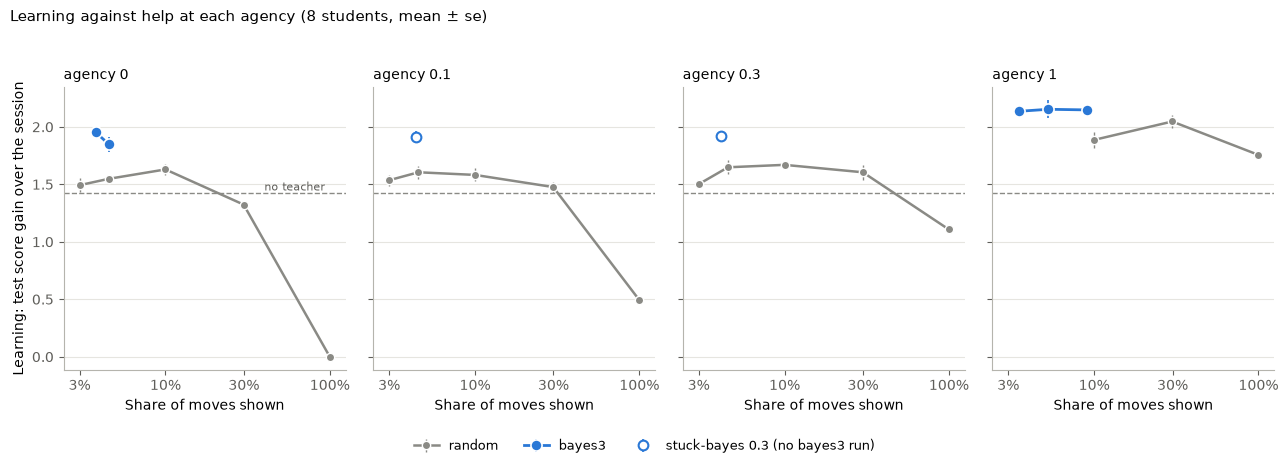

In [21]:
AGENCY_RUNS = {0: RUN, 0.1: "teach_shortcut_agency0.1", 0.3: "teach_shortcut_agency0.3", 1: AGENCY1_RUN}
RANDOM_ALL = ["random:0.03", "random:0.045", "random:0.1", "random:0.3", "random:1.0"]
BAYES3_AT = {0: ["stuck-bayes1:0.45,patience=0,giveup=0", "stuck-bayes1:0.6,patience=0,giveup=0"],
             1: ["bayes3:0.45", "bayes3:0.75", "bayes3:0.9"]}  # the same teacher, saved under its old name at agency 0
OTHER_AT = {0.1: ["stuck-bayes:0.3"], 0.3: ["stuck-bayes:0.3"]}  # bayes3 wasn't run there: the nearest targeted teacher


def gain(e, base):
    """Learning minus `base`'s, paired by student: (mean, se, k better, n)."""
    a, b = gains(e), gains(base)
    d = [a[s] - b[s] for s in a if s in b]
    m, s = te.mean_se(d)
    return m, s, sum(x > 0 for x in d), len(d)


def agency1_table(specs=None):
    none, rows = entry(NONE_RUN, "none"), []
    bases = [("vs no teacher", "none", none)] + [(f"vs random {p}", f"random:{q}", entry(AGENCY1_RUN, f"random:{q}"))
                                                 for p, q in (("10%", 0.1), ("30%", 0.3))]
    for spec in specs or AGENCY1:
        e = entry(AGENCY1_RUN, spec)
        if e is None:
            print(f"{se.teacher_name(spec)}: not saved yet")
            continue
        m, s = te.mean_se(learning(e))
        played = [x for r in e["sessions"].values() for x in r]
        row = {"teacher": se.teacher_name(spec), "shown": spend(e),
               "solved as played": np.mean([x["solved"] for x in played]),
               "examples per puzzle": np.mean([x["examples"] for x in played]),
               "learning": f"{m:+.3f} ± {s:.3f}"}
        for label, base_spec, base in bases:
            if base is not None and base_spec != spec:
                gm, gs, k, n = gain(e, base)
                row[label] = f"{gm:+.3f} ± {gs:.3f} ({k}/{n})"
        rows.append(row)
    return pd.DataFrame(rows).sort_values("shown").round(3)


def agency_figure(path):
    """Learning against help at each agency: random's curve (grey), bayes3 (blue), the nearest targeted teacher
    where bayes3 wasn't run (hollow blue), no teacher (dashed)."""
    agencies = list(AGENCY_RUNS)
    fig, axes = plt.subplots(1, len(agencies), figsize=(13, 4.6), sharey=True)
    base = np.mean(learning(entry(NONE_RUN, "none")))
    for ax, a in zip(axes, agencies):
        run = AGENCY_RUNS[a]
        ax.axhline(base, color="#8a8a85", lw=1, ls="--", zorder=0)
        pts = sorted((spend(e), *te.mean_se(learning(e))) for spec in RANDOM_ALL if (e := entry(run, spec)))
        if pts:
            x, m, s = map(np.array, zip(*pts))
            ax.errorbar(x, m, yerr=s, fmt="-o", color="#8a8a85", lw=1.8, ms=6, mec="white", mew=1, elinewidth=1,
                        capsize=0, label="random")
        pts = sorted((spend(e), *te.mean_se(learning(e))) for spec in BAYES3_AT.get(a, []) if (e := entry(run, spec)))
        if pts:
            x, m, s = map(np.array, zip(*pts))
            ax.errorbar(x, m, yerr=s, fmt="-o", color="#2a78d6", lw=2, ms=8, mec="white", mew=1.2, elinewidth=1.2,
                        capsize=0, label="bayes3", zorder=3)
        for spec in OTHER_AT.get(a, []):
            e = entry(run, spec)
            if e is not None:
                m, s = te.mean_se(learning(e))
                ax.errorbar(spend(e), m, yerr=s, fmt="o", color="#2a78d6", mfc="white", ms=7, mew=1.5,
                            elinewidth=1.2, capsize=0, label="stuck-bayes 0.3 (no bayes3 run)", zorder=3)
        ax.set_xscale("log")
        ax.set_xlim(0.024, 1.25)
        ax.set_xticks([0.03, 0.1, 0.3, 1.0], ["3%", "10%", "30%", "100%"])
        ax.minorticks_off()
        ax.set_title(f"agency {a:g}", fontsize=10, loc="left")
        ax.set_xlabel("Share of moves shown")
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#b5b4ad")
        ax.tick_params(colors="#5f5e5a")
        ax.grid(axis="y", color="#e6e5e0", lw=0.8)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Learning: test score gain over the session")
    axes[0].text(0.4, base + 0.02, "no teacher", color="#5f5e5a", fontsize=8)
    handles = {}
    for ax in axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            handles.setdefault(l, h)
    fig.legend(handles.values(), handles.keys(), loc="lower center", ncol=len(handles), frameon=False, fontsize=9)
    fig.suptitle("Learning against help at each agency (8 students, mean ± se)", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0.07, 1, 0.95))
    os.makedirs(os.path.dirname(path), exist_ok=True)
    plt.savefig(path, dpi=150)
    plt.show()


display(agency1_table())
agency_figure(os.path.join(FIGURES, "agency_curves.png"))

### Result: the dilemma survives at agency 1, and bayes3 is still the best teacher

**Full help still costs learning when shown moves teach fully.**
- Random 100% learns +1.76, 0.29 ± 0.07 less than random 30% (all 8 students worse) and 0.13 ± 0.08 less than random 10%.
- The prediction that learning would rise with help all the way to 100% was wrong.

**Why: help costs exploration, which agency doesn't touch.**
- The student learns from the shortest routes through every board its attempts visited (labels "all").
- A shown move keeps it on the optimal path. A fully shown puzzle leaves 17 examples, against 29-39 when the student wanders and finds its own way.
- So shown moves teach as much as found ones, but there are fewer of them, and none come from the boards the student would have got lost in.
- Lowering agency adds a second cost on top: what a shown move teaches.

**Random's peak moves right as agency rises.**
- About 8% shown at agency 0-0.1, 11% at 0.3, and somewhere between 10% and 100% at agency 1, near 30%.
- Agency 1 has only three random points, so its peak is rough.
- The high-help side keeps flattening: random 100% learns 0, +0.49, +1.11 and +1.76.

**bayes3 is flat from 3.5% to 9% shown at agency 1, and beats every random setting.**
- θ 0.45, 0.75 and 0.9 learn +2.14, +2.15 and +2.15.
- That is about 0.25 more than random 10% (7-8/8 students).
- It is about 0.1 more than random 30%, the best random setting at this agency (5-6/8 students, each about 1.5 se).
- bayes3's lead over the best random help shrinks with agency: +0.32 at agency 0 (against random 10%), +0.1 here.
- bayes3's curve isn't bracketed: it hasn't started to fall by 9%. So the help it should give at agency 1 is unknown beyond "at least 3.5%, and θ hardly matters up to 9%".
- At θ 0.45 spend is about the same as at agency 0 (3.5% against 3.8%), and learning is higher (+2.14 against +1.95), since the shown moves now count.

**Why the earlier pilot showed no dilemma at full agency.** The sweep notebook skipped agency 1 because of its first pilot. There, learning rose with help all the way to full help. That pilot was nominally at agency 0.1, but Adam cancelled the weight, and it cancelled it unevenly:
- With every move shown, every example in a batch weighs 0.1. Adam rescales that away, so full help ran at agency 1.
- With partial help, shown and own moves share a batch, and the 0.1 still counts between them. Shown moves taught a tenth as much as the student's own, so partial help ran at about agency 0.1.

So the pilot compared full help at agency 1 with partial help at agency 0.1, which favoured full help. Test scores after about 540 puzzles show this (the pilot tested at 360 and 720 puzzles, so its figures are interpolated):

| | pilot (about 540) | this run (540) |
|---|---|---|
| no teacher | about 4.92 | 4.78 (agency-0.3 run) |
| random 100% | about 4.66 | 4.64 |
| random 30% | about 4.73 | 4.41 |
| random 10% | about 4.79 | 4.50 |

Full help learns at the same rate in both. Partial help learns much faster once its shown moves count fully. The difference isn't session length: in this run random 100% is already 0.23 behind random 30% at 540 puzzles, and stays 0.3 behind to the end.

**For the question of realistic agency:** the assistance dilemma in this model doesn't depend on agency being very low. At agency 1 too much help still hurts, because it takes away the student's own search. And a teacher that helps only when the student is likely stuck still does best.

## Agency 1: where does bayes3's curve fall?

At agency 1, bayes3 learned the same at θ 0.45, 0.75 and 0.9 (3.5% to 9% shown), so the run didn't find where more
help starts to cost. Here bayes3 runs at higher thresholds, in the same run (same students, puzzles and tests).
Spend has grown by about 1.6× for each step of about 1.1 in logit θ (0.45 → 0.75 → 0.9), so:

- **θ 0.99:** expected near 30% shown, the same help as random's best setting at this agency. This is a direct comparison of when to help at the same amount.
- **θ 0.97:** expected around 15%.
- **θ 0.999:** expected well above 30%, to see the high-help side.

These are extrapolations. The solve chance may saturate, so the real spend is read from the run.

In [ ]:
AGENCY1_HIGH = ["bayes3:0.99", "bayes3:0.97", "bayes3:0.999"]
launch("agency1_high", AGENCY1_HIGH, run=AGENCY1_RUN, settings=AGENCY1_SETTINGS)

In [ ]:
watch("agency1_high")

In [ ]:
BAYES3_AT[1] = ["bayes3:0.45", "bayes3:0.75", "bayes3:0.9", "bayes3:0.97", "bayes3:0.99", "bayes3:0.999"]
display(agency1_table(AGENCY1 + AGENCY1_HIGH))
agency_figure(os.path.join(FIGURES, "agency_curves.png"))

### Result: bayes3 at agency 1 is flat up to about 9% shown and falls beyond that

| bayes3 θ | shown | examples per puzzle | learning | vs random 30% |
|---|---|---|---|---|
| 0.45 | 3.5% | 38.9 | +2.14 | +0.09 ± 0.07 (6/8) |
| 0.75 | 5.3% | 37.7 | +2.15 | +0.11 ± 0.09 (5/8) |
| 0.9 | 9.1% | 34.6 | +2.15 | +0.10 ± 0.06 (5/8) |
| 0.97 | 22% | 28.5 | +1.97 | −0.08 ± 0.06 (4/8) |
| 0.99 | 40% | 23.3 | +1.95 | −0.09 ± 0.06 (3/8) |
| 0.999 | 100% | 17.2 | +1.76 | −0.29 ± 0.07 (0/8) |

- **The curve is a plateau, then a decline.** bayes3 learns the same from 3.5% to 9% shown, then about 0.18 less at 22% and 40%, and 0.39 less at 100%.
  - A quadratic in log(share shown), as fitted at agency 0, doesn't describe a plateau: it puts the peak at 2.6% with an interval from 0% to 8%. So it isn't used here.
  - The useful summary is that anything from θ 0.45 to 0.9 is equally good at agency 1, and θ 0.45 stays the default.
- **At θ 0.999 bayes3 shows every move.** The model never gives the student a solve-alone chance above 0.999, so this is full help, and it matches random 100% (+1.76, the same examples).
- **At high help, targeted help no longer beats random.** At 22% and 40% shown, bayes3 is slightly below random 30% (−0.08 and −0.09, not significant).
  - The likely reason is the take-over pattern. With a high θ, once bayes3 steps in it keeps showing moves until the solve chance clears θ, so it removes whole stretches of the student's search. Random help spreads the same number of shown moves out.
  - The examples per puzzle fit this. bayes3 at 22% shown leaves 28.5 examples per puzzle, against 29.3 for random at 30%.
- **Overall at agency 1:** light targeted help (3.5–9%) is best, at about +2.15. That is about 0.1 above random's best (30%) and 0.39 above full help. Learning roughly follows the examples the student's own search produces: across the nine teachers, the more examples per puzzle, the more learning. The exception is random 10%, which learns less than its 32 examples per puzzle would suggest. Example count isn't the whole story.

## Limited hindsight: which labels survive?

Shortcut labels assume the student remembers every board it visited and notices every one-move connection between
them. People can't do that. This checks, without training anything, how much of what made shortcut labels work
survives a human-like limit.

`scripts/hindsight_labels.py` has the starting network play 600 session puzzles (150 per bin, as in the agency-1
run: temperature 1, memory 10, a cap of max(50, 10 d), giving up at 0.4× people's rates). It then labels each solved
attempt in several ways, and scores every label against exact (BFS) distances:

- **own:** the path played with loops cut out, the labels used before shortcut labels;
- **walk (W=1):** shortest routes using only the moves actually played;
- **W = w:** shortcut labels, but a one-move connection between two visited boards is noticed only if the student was
  at them within w moves of each other. W = inf is today's "all" labels;
- **path:** today's "path" labels (boards on shortest routes from the start);
- **near D:** shortcut labels only on boards at most D moves from the goal: label less, but only what is reliable.

"Off-path" boards lie off every optimal path from the start: coverage a fully shown solution never gives.

In [ ]:
import json

HINDSIGHT = json.load(open(os.path.join(OUT, "hindsight_labels.json")))
print(f"{HINDSIGHT['n']} puzzles, {HINDSIGHT['solved']} solved")
display(pd.DataFrame(HINDSIGHT["table"]).set_index("labels").round(3))

### Result: a recency window keeps the coverage and most of the label quality

| labels | labels per puzzle | off-path | targets optimal | distance / true |
|---|---|---|---|---|
| own | 24.0 | 16.4 | 54.5% | 2.42 |
| walk (W=1) | 32.3 | 23.3 | 51.2% | 2.35 |
| W=5 | 32.3 | 23.3 | 56.5% | 1.81 |
| W=10 | 32.3 | 23.3 | 58.9% | 1.68 |
| W=20 | 32.3 | 23.3 | 60.6% | 1.61 |
| W=inf (all) | 32.3 | 23.3 | 63.3% | 1.56 |
| path | 16.2 | 9.5 | 71.3% | 1.50 |
| near 10 | 9.3 | 6.3 | 69.6% | 1.34 |
| near 5 | 3.9 | 2.5 | 77.8% | 1.22 |

**Coverage doesn't need full hindsight.**
- Every windowed variant labels the same 32 boards per puzzle, 23 of them off every optimal path. The moves the student actually played always link each visited board to the goal. A window changes how good the labels are, not which boards get one.
- Own labels lose a quarter of those boards, because cutting loops discards the boards inside them.

**Label quality falls gradually as the window shrinks.**
- W=10 has 1.68× the true distance against 1.56× for full hindsight and 2.42× for own labels. That is 86% of full hindsight's improvement in distance, and about half of its improvement in optimal targets (58.9% against 63.3%, from 54.5%).
- W=5 keeps 70% of the distance improvement but only about a quarter of the improvement in target moves.
- With no shortcuts at all (W=1), the target moves are worse than own labels (51%), since the boards inside loops are now labelled too.

**Harder puzzles need a longer window.** On 24-26 move puzzles, W=10 reaches 60% optimal targets against 67% with full hindsight. On 9-11 move puzzles it reaches 60% against 62%.

**Labelling only near the goal trades away coverage.** The labels are much better (70-78% optimal, 1.2-1.3×), but there are only 4-9 per puzzle, and 2-6 off-path. That removes most of what the student gains by exploring, so it would likely weaken the exploration effect the most.

**What this doesn't settle.** It doesn't show which property drives learning and the dilemma: the number of labels, distance accuracy, or move accuracy. That needs training.
- The offline test in the sweep notebook showed shortcut labels learning far more than own labels, but it didn't separate these properties.
- These attempts are the starting network's. Later in a session, attempts get shorter and loops rarer.

**Next:** short agency-1 sessions with W=10 and W=5 (and own labels as the control), each with random 30% and 100%. These would show whether the dilemma survives a human-like limit on hindsight.

## Does the dilemma survive limited hindsight? Agency 1 at W = 10, W = 5 and own labels

The label analysis above showed that a recency window keeps every visited board labelled but makes the labels less
accurate. Here the window goes into the student (`--window` now also limits shortcut labels: rl.shortcut_routes
notices a connection only between boards visited within W moves of each other). Each label setting gets its own run
at agency 1, with the agency-1 run's settings, students, puzzles and tests otherwise:

- **W = 10** and **W = 5:** limited hindsight;
- **own labels** (loops cut out, no shortcuts): the student before shortcut labels, with which more help always
  seemed better. This is the control for the explanation that shortcut labels are what make exploration pay.

Each has no teacher, random 30% (random's best at agency 1 with full hindsight) and random 100%. No teacher learns
differently under each label setting, so each needs its own. Full hindsight is the agency-1 run above (no teacher
from the agency-0.3 run, which is the same student with no shown moves).

**The question:** is random 100% still below random 30%? With full hindsight it is 0.29 ± 0.07 below. Nine teacher runs,
about 3 hours, queued in the order W = 10, own, W = 5.

In [ ]:
HINDSIGHT_TEACHERS = ["random:1.0", "random:0.3", "none"]
HINDSIGHT_RUNS = {"W=10": ("teach_shortcut_agency1_w10", {**AGENCY1_SETTINGS, "window": 10}),
                  "own": ("teach_own_agency1", {**AGENCY1_SETTINGS, "labels": "own"}),
                  "W=5": ("teach_shortcut_agency1_w5", {**AGENCY1_SETTINGS, "window": 5})}
os.chdir("../scripts")  # the runs resolve relative paths (--init) from scripts/
try:
    rq.launch("hindsight_agency1", [(run, argv(s) + ["--teachers", *HINDSIGHT_TEACHERS])
                                    for run, s in HINDSIGHT_RUNS.values()])
finally:
    os.chdir("../notebooks")

In [ ]:
watch("hindsight_agency1")

In [ ]:
HINDSIGHT_ALL = {"full (W=inf)": (AGENCY1_RUN, NONE_RUN)} | {k: (run, run) for k, (run, _) in HINDSIGHT_RUNS.items()}
HINDSIGHT_ORDER = ["full (W=inf)", "W=10", "W=5", "own"]


def hindsight_table():
    """Per label setting: each teacher's learning, and the paired differences that matter."""
    rows = []
    for name in HINDSIGHT_ORDER:
        run, none_run = HINDSIGHT_ALL[name]
        e = {"none": entry(none_run, "none"), "random:0.3": entry(run, "random:0.3"), "random:1.0": entry(run, "random:1.0")}
        row = {"hindsight": name}
        for spec, x in e.items():
            if x is None:
                row[se.teacher_name(spec)] = "not saved yet"
                continue
            m, s = te.mean_se(learning(x))
            played = [r for rec in x["sessions"].values() for r in rec]
            row[se.teacher_name(spec)] = f"{m:+.3f} ± {s:.3f}"
            row[f"examples ({spec.split(':')[-1]})"] = round(np.mean([r["examples"] for r in played]), 1)
            row[f"solved ({spec.split(':')[-1]})"] = round(np.mean([r["solved"] for r in played]), 2)
        for label, a, b in (("30% vs none", "random:0.3", "none"), ("100% vs 30%", "random:1.0", "random:0.3")):
            if e[a] is not None and e[b] is not None:
                gm, gs, k, n = gain(e[a], e[b])
                row[label] = f"{gm:+.3f} ± {gs:.3f} ({k}/{n})"
        rows.append(row)
    return pd.DataFrame(rows).set_index("hindsight")


def hindsight_figure(path):
    """Learning against help (none, 30%, 100%) at agency 1, one line per label setting."""
    fig, ax = plt.subplots(figsize=(8, 5))
    colors = {"full (W=inf)": "#1f1f1d", "W=10": "#2a78d6", "W=5": "#7fb2ea", "own": "#eb6834"}
    for name in HINDSIGHT_ORDER:
        run, none_run = HINDSIGHT_ALL[name]
        pts = []
        for x_pos, spec, r in ((0.01, "none", none_run), (0.3, "random:0.3", run), (1.0, "random:1.0", run)):
            e = entry(r, spec)
            if e is not None:
                pts.append((x_pos, *te.mean_se(learning(e))))
        if pts:
            x, m, s = map(np.array, zip(*pts))
            ax.errorbar(x, m, yerr=s, fmt="-o", color=colors[name], lw=2, ms=7, mec="white", mew=1.2,
                        elinewidth=1.2, capsize=0, label=name)
    ax.legend(title="hindsight", loc="lower right", frameon=False, fontsize=9, title_fontsize=9)
    ax.set_xscale("log")
    ax.set_xlim(0.007, 1.5)
    ax.set_xticks([0.01, 0.3, 1.0], ["no teacher", "random 30%", "random 100%"])
    ax.minorticks_off()
    ax.set_ylabel("Learning: test score gain over the session")
    ax.set_title("Agency 1: learning against help, by how much hindsight the student has (8 students, mean ± se)",
                 fontsize=10, loc="left")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#b5b4ad")
    ax.tick_params(colors="#5f5e5a")
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    ax.set_axisbelow(True)
    plt.tight_layout()
    os.makedirs(os.path.dirname(path), exist_ok=True)
    plt.savefig(path, dpi=150)
    plt.show()


display(hindsight_table())
hindsight_figure(os.path.join(FIGURES, "hindsight_agency1.png"))

### Result: the dilemma comes from shortcut labels, and survives a 10-move hindsight window

| hindsight | no teacher | random 30% | random 100% | 100% vs 30% (paired) |
|---|---|---|---|---|
| full (W=inf) | +1.43 | +2.05 | +1.76 | −0.29 ± 0.07 (0/8 better) |
| W=10 | +1.35 | +2.01 | +1.72 | −0.30 ± 0.03 (0/8) |
| W=5 | +1.12 | +1.90 | +1.68 | −0.22 ± 0.06 (2/8) |
| own labels | +0.01 | +1.39 | +1.76 | **+0.37 ± 0.03 (8/8)** |

- **Own labels: no dilemma.** More help is better at every step, as in the runs before shortcut labels.
  - Left alone, the student learns nothing (+0.01): its loop-cut paths are poor targets, so 23 examples a puzzle
    of its own play are worth nothing.
  - Random 100% beats random 30% by 0.37 for all 8 students.
  - This confirms the explanation in the agency-1 section: the dilemma needs a student who can learn from its own
    wandering, and here that ability comes from shortcut labels. Agency 1 by itself does not produce it.
- **A 10-move window keeps all of it.** 100% vs 30% is −0.30 (0/8), the same as full hindsight. No teacher drops
  only 0.08.
- **A 5-move window keeps most of it.** The gap shrinks to −0.22 (2/8 students go the other way). The student's own
  play is worth less (no teacher +1.12), so a little help is worth more (30% vs none +0.78, against +0.62).
- **Random 100% is the same in every row** (17.2 examples, 98% solved), as it should be: a fully shown solution has
  no wandering, so every label setting gives the same labels. The spread of 0.08 across rows (+1.68 to +1.76) is
  therefore run-to-run noise. Comparisons across rows are not paired by run and should be read against that.
- **The order matches the label analysis.** The shorter the window, the less the student gains from its own play,
  and the smaller the dilemma. The analysis predicted W=10 would keep most of the distance accuracy, and it does.

**What this means for the model.** The assistance dilemma here rests on one assumption: that a learner who solves
a puzzle can work out, afterwards, better routes through the boards it visited. Limiting that to boards visited
within 10 moves of each other, which is closer to human memory, loses none of the effect. A student who can only
reuse its own path with loops cut out shows no dilemma at all. Whether people learn like the shortcut student or the
own-labels student is now the key empirical question, and the two predict opposite effects of full help.

## Exploring the hindsight window

Four analyses of how limited hindsight shapes the dilemma and the teacher, all at agency 1:

1. **When in the session** the cost of full help appears, at each window (the test snapshots after 540, 1080, 1620 and 2160 puzzles).
2. **Which puzzle lengths** carry it: the end-of-session gap on each test-length bin.
3. **What bayes3's help does to the labels**: a replay of the session start with each teacher, labelled at each window (`scripts/hindsight_teacher_labels.py`).
4. **bayes3 across the help range at each window**: θ 0.45, 0.9, 0.97 (and 0.99 at W=5 and own), in the W=10, W=5 and own-label runs.

Two more sets of runs feed these:
- **Lower windows at agency 1:** W=3 and W=1 with no teacher, random 30% and random 100%.
- **The people-calibrated student** (`rush_hour_session.ipynb`: the humans' puzzle lengths, starting level and giving up) with no teacher, under own labels and W = 1, 3, 5, 10 and unlimited. Its learning is compared with people's, to see which window people's learning looks like. The agency-1 runs use much longer puzzles, so they can't be compared with people.

One queue, 23 teacher runs, about 8 hours.

In [ ]:
# Lower windows at agency 1 (no teacher, random 30%, random 100%), as for W=10 and W=5.
LOW_W_RUNS = {"W=3": ("teach_shortcut_agency1_w3", {**AGENCY1_SETTINGS, "window": 3}),
              "W=1": ("teach_shortcut_agency1_w1", {**AGENCY1_SETTINGS, "window": 1})}
# The people-calibrated student (rush_hour_session.ipynb's CALIBRATED: the humans' puzzle lengths, own labels),
# with no teacher, under each kind of hindsight.
INIT = "../models/teach/fresh_p0.1/random_0.1/round6_epoch01.pt"
PEOPLE_SETTINGS = {"students": 8, "multiplier": 30, "lr": 1e-4, "window": -1, "steps": 3, "max_attempts": 1,
                   "surrender": True, "test_surrender": True, "surrender_scale": 0.4, "init": INIT}
PEOPLE_RUNS = {"own": ("people_own", {**PEOPLE_SETTINGS, "labels": "own"}),
               "W=1": ("people_w1", {**PEOPLE_SETTINGS, "labels": "all", "window": 1}),
               "W=3": ("people_w3", {**PEOPLE_SETTINGS, "labels": "all", "window": 3}),
               "W=5": ("people_w5", {**PEOPLE_SETTINGS, "labels": "all", "window": 5}),
               "W=10": ("people_w10", {**PEOPLE_SETTINGS, "labels": "all", "window": 10}),
               "full (W=inf)": ("people_all", {**PEOPLE_SETTINGS, "labels": "all", "window": -1})}
# bayes3 across the help range at each window (full hindsight already has θ 0.45-0.999).
BAYES3_W = {"W=10": ["bayes3:0.45", "bayes3:0.9", "bayes3:0.97"],
            "W=5": ["bayes3:0.45", "bayes3:0.9", "bayes3:0.97", "bayes3:0.99"],
            "own": ["bayes3:0.45", "bayes3:0.9", "bayes3:0.97", "bayes3:0.99"]}

jobs = ([(run, argv(s) + ["--teachers", "none", "random:0.3", "random:1.0"]) for run, s in LOW_W_RUNS.values()]
        + [(run, argv(s) + ["--teachers", "none"]) for run, s in PEOPLE_RUNS.values()]
        + [(HINDSIGHT_RUNS[w][0], argv(HINDSIGHT_RUNS[w][1]) + ["--teachers", *specs]) for w, specs in BAYES3_W.items()])
os.chdir("../scripts")  # the runs resolve relative paths (--init) from scripts/
try:
    rq.launch("hindsight_explore", jobs)
finally:
    os.chdir("../notebooks")

In [ ]:
watch("hindsight_explore")

In [ ]:
WINDOWS = {"full (W=inf)": (AGENCY1_RUN, NONE_RUN), "W=10": (HINDSIGHT_RUNS["W=10"][0],) * 2,
           "W=5": (HINDSIGHT_RUNS["W=5"][0],) * 2, "W=3": (LOW_W_RUNS["W=3"][0],) * 2,
           "W=1": (LOW_W_RUNS["W=1"][0],) * 2, "own": (HINDSIGHT_RUNS["own"][0],) * 2}
WINDOW_COLORS = {"full (W=inf)": "#1f1f1d", "W=10": "#1c5aa8", "W=5": "#2a78d6", "W=3": "#7fb2ea", "W=1": "#b9d5f5",
                 "own": "#eb6834"}


def window_entries(name):
    """{"none", "random:0.3", "random:1.0"} entries of a hindsight setting (None where not saved)."""
    run, none_run = WINDOWS[name]
    return {"none": entry(none_run, "none"), "random:0.3": entry(run, "random:0.3"),
            "random:1.0": entry(run, "random:1.0")}


def scores_at(e, n, lo=None, hi=None):
    """{student: test score after n puzzles}, over the test puzzles of optimal length lo..hi (default: all)."""
    out = {}
    for s, by_n in e["results"].items():
        if n in by_n:
            a = [x for x in by_n[n] if lo is None or lo <= x["distance"] <= hi]
            out[s] = measures(a, e["config"])[0]
    return out


def gap(a, b, n, lo=None, hi=None):
    """Learning of a minus learning of b after n puzzles, paired by student (a lower score is better):
    (mean, se, students where a is ahead, students)."""
    sa, sb = scores_at(a, n, lo, hi), scores_at(b, n, lo, hi)
    d = [sb[s] - sa[s] for s in sa if s in sb]
    m, s = te.mean_se(d)
    return m, s, sum(x > 0 for x in d), len(d)


def fmt(g):
    return f"{g[0]:+.2f} ± {g[1]:.2f} ({g[2]}/{g[3]})"


def saved_windows():
    return [w for w in WINDOWS if all(v is not None for v in window_entries(w).values())]


def time_table():
    """Per window and test point: 30% vs none and 100% vs 30%."""
    rows = []
    for w in saved_windows():
        e = window_entries(w)
        points = sorted(n for n in e["none"]["results"][0] if n > 0)
        for label, a, b in (("30% vs none", "random:0.3", "none"), ("100% vs 30%", "random:1.0", "random:0.3")):
            rows.append({"hindsight": w, "comparison": label} | {f"after {n}": fmt(gap(e[a], e[b], n)) for n in points})
    return pd.DataFrame(rows).set_index(["hindsight", "comparison"])


def time_figure(path):
    """Learning along the session, one panel per window: no teacher (dashed), random 30%, random 100%."""
    ws = saved_windows()
    fig, axes = plt.subplots(1, len(ws), figsize=(3.1 * len(ws), 3.8), sharey=True)
    styles = {"none": ("#8a8a85", "--", "no teacher"), "random:0.3": ("#2a78d6", "-", "random 30%"),
              "random:1.0": ("#eb6834", "-", "random 100%")}
    for ax, w in zip(np.atleast_1d(axes), ws):
        e = window_entries(w)
        start = measures(e["none"]["results"][0][0], e["none"]["config"])[0]
        for spec, (c, ls, label) in styles.items():
            pts = [(n, *te.mean_se([start - v for v in scores_at(e[spec], n).values()]))
                   for n in sorted(e[spec]["results"][0])]
            x, m, s = map(np.array, zip(*pts))
            ax.fill_between(x, m - s, m + s, color=c, alpha=0.15, lw=0)
            ax.plot(x, m, ls, color=c, lw=2, marker="o", ms=5, mec="white", mew=1, label=label)
        ax.set_title(w, fontsize=10, loc="left")
        ax.set_xticks([0, 1080, 2160])
        ax.set_xlabel("Puzzles played")
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#b5b4ad")
        ax.tick_params(colors="#5f5e5a")
        ax.grid(axis="y", color="#e6e5e0", lw=0.8)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Learning so far (test score gain)")
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=3, frameon=False, fontsize=9)
    fig.suptitle("Agency 1: learning along the session, by hindsight (8 students, mean ± se)", x=0.01, ha="left",
                 fontsize=11)
    plt.tight_layout(rect=(0, 0.08, 1, 0.94))
    os.makedirs(os.path.dirname(path), exist_ok=True)
    plt.savefig(path, dpi=150)
    plt.show()


def examples_in(e, lo, hi):
    """Training examples per session puzzle of optimal length lo..hi."""
    return np.mean([x["examples"] for rec in e["sessions"].values() for x in rec if lo <= x["distance"] <= hi])


def bin_figure(path):
    """100% vs 30% at the end of the session, by test-puzzle length, one line per window."""
    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    ax.axhline(0, color="#8a8a85", lw=1)
    for w in saved_windows():
        e = window_entries(w)
        end = max(e["none"]["results"][0])
        bins = e["none"]["config"]["test_bins"]
        pts = [gap(e["random:1.0"], e["random:0.3"], end, *map(int, b.split("-")))[:2] for b in bins]
        m, s = map(np.array, zip(*pts))
        x = np.arange(len(bins))
        ax.errorbar(x, m, yerr=s, fmt="-o", color=WINDOW_COLORS[w], lw=2, ms=7, mec="white", mew=1.2,
                    elinewidth=1.2, capsize=0, label=w)
    ax.set_xticks(np.arange(len(bins)), [f"{b} moves" for b in bins])
    ax.set_xlabel("Test puzzles' optimal length")
    ax.set_ylabel("Learning: random 100% minus random 30%")
    ax.text(len(bins) - 1, 0.03, "full help better", ha="right", va="bottom", fontsize=9, color="#5f5e5a")
    ax.text(len(bins) - 1, -0.03, "full help worse", ha="right", va="top", fontsize=9, color="#5f5e5a")
    ax.legend(title="hindsight", frameon=False, fontsize=9, title_fontsize=9, loc="lower left")
    ax.set_title("Agency 1: the cost of full help, by puzzle length (end of session, 8 students, mean ± se)",
                 fontsize=10, loc="left")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#b5b4ad")
    ax.tick_params(colors="#5f5e5a")
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()


def bin_table():
    """Per window and test-puzzle length bin, at the end of the session: no teacher's learning, and the gaps."""
    rows = []
    for w in saved_windows():
        e = window_entries(w)
        end = max(e["none"]["results"][0])
        start_all = e["none"]["results"][0][0]
        for b in e["none"]["config"]["test_bins"]:
            lo, hi = map(int, b.split("-"))
            start = measures([x for x in start_all if lo <= x["distance"] <= hi], e["none"]["config"])[0]
            m, s = te.mean_se([start - v for v in scores_at(e["none"], end, lo, hi).values()])
            rows.append({"hindsight": w, "length": b, "start score": round(start, 2),
                         "no teacher learns": f"{m:+.2f} ± {s:.2f}",
                         "30% vs none": fmt(gap(e["random:0.3"], e["none"], end, lo, hi)),
                         "100% vs 30%": fmt(gap(e["random:1.0"], e["random:0.3"], end, lo, hi)),
                         "examples: none": examples_in(e["none"], lo, hi),
                         "examples: 30%": examples_in(e["random:0.3"], lo, hi),
                         "examples: 100%": examples_in(e["random:1.0"], lo, hi)})
    return pd.DataFrame(rows).set_index(["hindsight", "length"]).round(3)


display(time_table())
time_figure(os.path.join(FIGURES, "hindsight_time.png"))
display(bin_table())
bin_figure(os.path.join(FIGURES, "hindsight_by_length.png"))

### 1-2. Results: when the cost appears, and on which puzzles

**Lower windows.** The dilemma ends between W=5 and W=3:

| hindsight | 100% vs 30% at the end | 30% vs none |
|---|---|---|
| full | −0.29 (0/8) | +0.62 |
| W=10 | −0.30 (0/8) | +0.66 |
| W=5 | −0.22 (2/8) | +0.78 |
| W=3 | −0.04 ± 0.07 (3/8) | +0.91 |
| W=1 | **+0.26 ± 0.04 (8/8)** | +1.56 |
| own | **+0.37 ± 0.03 (8/8)** | +1.38 |

At W=1 the shortcut labels are only shortest routes through the moves actually played. With no teacher they teach about nothing (−0.27 to +0.11 by length), so W=1 behaves like own labels.

**Over the session (analysis 1).**
- With a window of 5 or more, the cost of full help is there from the first snapshot and grows a little: W=10 goes from −0.15 after 540 puzzles to −0.30 at the end, and full hindsight from −0.23 to −0.29. W=5 is noisy (−0.11, −0.08, −0.05, −0.22).
- At W=3 the gap is about zero at every snapshot. At W=1 and with own labels, full help is ahead from the first snapshot.
- So a teacher that fades its help over the session has little to gain here. Where the dilemma exists, it is there early.

**By puzzle length (analysis 2).** This is the clearest pattern:
- **On the shortest test puzzles (9-11 moves), full help is better at every window,** by +0.10 to +0.35.
- **The cost is on the long puzzles.** On 24-26 moves it is −0.76 with full hindsight and −0.64 at W=10 and W=5. It is still −0.24 at W=3, where the shortest puzzles gain +0.20. W=3's overall zero is a cost on long puzzles averaging out a benefit on short ones.
- **Coverage explains it.** On 24-26-move session puzzles, random 30% gives 46 examples per puzzle, no teacher 28 and full help 25. On 9-11-move puzzles the student hardly wanders, and full help (10 examples) is close to the others (14-17), so the exact labels of a shown solution win.
- **What this means for a teacher:** help on short puzzles is close to free, while on long puzzles it should leave room for search. That is the opposite of a rule that steps in when the solve chance is low, which happens mostly on long puzzles.

### 3. What a teacher's help does to the labels

`scripts/hindsight_teacher_labels.py` replays the first 540 puzzles of two students' full-hindsight sessions with each teacher (same seeds and learning, so each teacher acts as in the run). It records every attempt and labels every third puzzle at each window, scored against exact distances as in "Limited hindsight". The replay is from the full-hindsight student, so at a short window the student itself would have learned a little differently.

In [ ]:
import json
TL = json.load(open(os.path.join(OUT, "hindsight_teacher_labels.json")))
rows = []
for spec, r in TL["teachers"].items():
    t = {x["labels"]: x for x in r["table"]}
    row = {"teacher": se.teacher_name(spec), "shown": r["shown"], "solved": r["solved"],
           "moves per puzzle": r["moves per puzzle"], "labels per puzzle (own)": t["own"]["labels per puzzle"],
           "labels per puzzle (shortcut)": t["W=inf (all)"]["labels per puzzle"],
           "off-path labels per puzzle": t["W=inf (all)"]["off-path per puzzle"]}
    row |= {f"distance / true, {k}": t[k]["distance / true"] for k in ("own", "walk (W=1)", "W=3", "W=5", "W=10", "W=inf (all)")}
    rows.append(row)
print(f"First {TL['puzzles']} puzzles of {TL['students']} students' sessions, every {TL['every']}rd puzzle scored")
display(pd.DataFrame(rows).set_index("teacher").round(3))

**Result.**
- **bayes3 at low θ gives the most labels.** At θ 0.45 (3.8% shown) it gives 45 labels per puzzle, 30 of them off the solution path. No teacher gives 31 and random 30% gives 33. bayes3 rescues the student (84% solved against 67%) but only after long wandering (69 moves per puzzle), and an unsolved puzzle gives no labels at all.
- **Those labels are no more accurate than the unhelped student's,** at any window. Label distance against the true distance at W=5 is 1.59 for bayes3 0.45, 1.60 for no teacher and 1.35 for random 30%; at W=3 it is 1.70, 1.70 and 1.41. Random 30% keeps the student near the solution, so its detours are short, and a short window can work out shortcuts in short detours.
- **At the same spend, bayes3 gives fewer labels.** At about 30% shown, bayes3 0.97 gives 27 labels per puzzle (11 off the path) against random 30%'s 33 (18). Its take-over runs remove whole stretches of search. This is consistent with bayes3 doing slightly worse than random 30% at high θ.

So bayes3's value is quantity: it turns long, would-be-unsolved wanderings into labelled puzzles. That is worth most to a student with full hindsight, which can find shortcuts across a long wander.

In [ ]:
BAYES3_SWEEP = {"full (W=inf)": ["bayes3:0.45", "bayes3:0.75", "bayes3:0.9", "bayes3:0.97", "bayes3:0.99"], **BAYES3_W}
SWEEP_ORDER = ["full (W=inf)", "W=10", "W=5", "own"]


def bayes3_window_table():
    rows = []
    for w in SWEEP_ORDER:
        run = WINDOWS[w][0]
        e = window_entries(w)
        for spec in ["none", "random:0.3", "random:1.0"] + BAYES3_SWEEP[w]:
            x = e.get(spec) or entry(run, spec)
            if x is None:
                continue
            m, s = te.mean_se(learning(x))
            row = {"hindsight": w, "teacher": se.teacher_name(spec), "shown": spend(x),
                   "learning": f"{m:+.3f} ± {s:.3f}"}
            if spec.startswith("bayes3"):
                row["vs random 30%"] = fmt(gain(x, e["random:0.3"]))
                row["vs random 100%"] = fmt(gain(x, e["random:1.0"]))
            rows.append(row)
    return pd.DataFrame(rows).set_index(["hindsight", "teacher"]).round(3).fillna("")


def bayes3_window_figure(path):
    """Learning against share shown at each window: random (none at the left edge, 30%, 100%) and bayes3."""
    fig, axes = plt.subplots(1, len(SWEEP_ORDER), figsize=(13, 4.4), sharey=True)
    for ax, w in zip(axes, SWEEP_ORDER):
        run, e = WINDOWS[w][0], window_entries(w)
        m0, s0 = te.mean_se(learning(e["none"]))
        ax.axhline(m0, color="#8a8a85", lw=1, ls="--", zorder=0)
        pts = [(spend(e[k]), *te.mean_se(learning(e[k]))) for k in ("random:0.3", "random:1.0")]
        x, m, s = map(np.array, zip(*pts))
        ax.errorbar(x, m, yerr=s, fmt="-o", color="#8a8a85", lw=1.8, ms=6, mec="white", mew=1, elinewidth=1,
                    capsize=0, label="random")
        pts = sorted((spend(x), *te.mean_se(learning(x))) for spec in BAYES3_SWEEP[w] if (x := entry(run, spec)))
        x, m, s = map(np.array, zip(*pts))
        ax.errorbar(x, m, yerr=s, fmt="-o", color="#2a78d6", lw=2, ms=7, mec="white", mew=1.2, elinewidth=1.2,
                    capsize=0, label="bayes3", zorder=3)
        ax.set_xscale("log")
        ax.set_xlim(0.025, 1.3)
        ax.set_xticks([0.03, 0.1, 0.3, 1.0], ["3%", "10%", "30%", "100%"])
        ax.minorticks_off()
        ax.set_title(w, fontsize=10, loc="left")
        ax.set_xlabel("Share of moves shown")
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#b5b4ad")
        ax.tick_params(colors="#5f5e5a")
        ax.grid(axis="y", color="#e6e5e0", lw=0.8)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Learning: test score gain over the session")
    axes[0].text(0.027, m0 + 0.03, "no teacher", color="#5f5e5a", fontsize=8)
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=2, frameon=False, fontsize=9)
    fig.suptitle("Agency 1: bayes3 and random across the help range, by hindsight (8 students, mean ± se; "
                 "dashed: no teacher)", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0.07, 1, 0.94))
    plt.savefig(path, dpi=150)
    plt.show()


display(bayes3_window_table())
bayes3_window_figure(os.path.join(FIGURES, "hindsight_bayes3.png"))

### 4. Result: bayes3's edge depends on full hindsight

| hindsight | bayes3 vs random 30% (θ 0.45 / 0.9 / 0.97) | best teacher |
|---|---|---|
| full | +0.09 (6/8) / +0.10 (5/8) / −0.08 (4/8) | bayes3 θ 0.45-0.9 (+2.14) |
| W=10 | −0.03 (3/8) / +0.01 (6/8) / −0.11 (1/8) | random 30% and bayes3 0.9 tie (+2.01) |
| W=5 | −0.16 (1/8) / −0.15 (1/8) / −0.15 (2/8); θ 0.99 −0.09 | random 30% (+1.90) |
| own | −1.14 / −0.54 / −0.07; θ 0.99 +0.15 (7/8) | random 100% (+1.76) |

- **As hindsight shrinks, bayes3 loses its edge over random 30%.** At W=5 it is flat (+1.74 to +1.81 from 3.6% to 41% shown) and below random 30% at every θ. The amount of help doesn't matter there, so the cost comes from when it helps. Analysis 3 gives the reason: bayes3's labels come from long wanders, which a short window can't use.
- **With own labels, more help is simply better,** and bayes3 tracks random's curve. Random 100% is the best teacher.
- **bayes3 still beats full help at every window with shortcut labels** (+0.05 to +0.40), so it isn't harmful. It just isn't the right kind of help once hindsight is short.

bayes3 wasn't run at W=3. The next section suggests W=3 is the closest to people, so its ranking there is the one that matters most.

In [ ]:
import human_data as hd

PEOPLE_ORDER = ["own", "W=1", "W=3", "W=5", "W=10", "full (W=inf)"]
PEOPLE_COLORS = {"own": "#eb6834", "W=1": "#b9d5f5", "W=3": "#7fb2ea", "W=5": "#2a78d6", "W=10": "#1c5aa8",
                 "full (W=inf)": "#1f1f1d"}
SPLIT, BLOCK = 30, 10
HUMANS = hd.trials()


def played(name):
    """The no-teacher session of a people-calibrated run, one row per puzzle (trial = the human trial it counts
    toward: 30 simulated puzzles each), or None until saved."""
    e = entry(PEOPLE_RUNS[name][0], "none")
    if e is None:
        return None
    return pd.DataFrame([x | {"student": s} for s, rec in e["sessions"].items() for x in rec])


def trend_rows(df, learner, person, puzzle):
    """Within-learner change per 10 trials (hd.trend: each learner and puzzle compared with itself), in trials
    1..SPLIT and after: solve rate, and log moves / optimal over solved puzzles (-0.05: about 5% fewer moves)."""
    row = {"learner": learner}
    for label, part in ((f"1-{SPLIT}", df[df.trial <= SPLIT]), (f"{SPLIT + 1}+", df[df.trial > SPLIT])):
        won = part[part.solved].assign(log_ratio=lambda d: np.log(d.moves / d.distance))
        sb, sse = hd.trend(part.assign(solved_f=part.solved.astype(float)), "solved_f", person=person, puzzle=puzzle)
        rb, rse = hd.trend(won, "log_ratio", person=person, puzzle=puzzle)
        row[f"moves/optimal, trials {label}"] = f"{rb:+.3f} ± {rse:.3f}"
        row[f"solve rate, trials {label}"] = f"{sb:+.1%} ± {sse:.1%}"
        row[f"_b {label}"], row[f"_se {label}"] = rb, rse
    first = df[df.trial <= BLOCK]
    won = first[first.solved]
    row["first 10 trials: solved"] = first.solved.mean()
    row["first 10 trials: moves/optimal"] = (won.moves / won.distance).mean()
    return row


def people_table():
    rows = [trend_rows(HUMANS, "humans", "subject", "instance")]
    for name in PEOPLE_ORDER:
        df = played(name)
        if df is not None:
            rows.append(trend_rows(df, name, "student", "puzzle"))
    t = pd.DataFrame(rows).set_index("learner")
    h_b, h_se = t.loc["humans", f"_b 1-{SPLIT}"], t.loc["humans", f"_se 1-{SPLIT}"]
    t[f"early vs humans (z)"] = (t[f"_b 1-{SPLIT}"] - h_b) / np.sqrt(t[f"_se 1-{SPLIT}"] ** 2 + h_se ** 2)
    return t.drop(columns=[c for c in t if c.startswith("_")]).round(3)


def block_curve(df, person):
    """Per block of 10 trials: (middle trial, mean and se across learners of each one's moves / optimal over its
    solved puzzles in the block)."""
    df = df.assign(block=(df.trial - 1) // BLOCK)
    out = []
    for b, d in df.groupby("block"):
        won = d[d.solved]
        out.append((b * BLOCK + BLOCK / 2 + 0.5, *te.mean_se(list((won.moves / won.distance).groupby(won[person]).mean()))))
    return out


def people_figure(path):
    """Moves / optimal (solved puzzles) along the session: people against the calibrated student at each window."""
    fig, ax = plt.subplots(figsize=(8.5, 5))
    x, m, s = map(np.array, zip(*block_curve(HUMANS, "subject")))
    ax.fill_between(x, m - s, m + s, color="#8a8a85", alpha=0.2, lw=0)
    ax.plot(x, m, "-o", color="#8a8a85", lw=2.5, ms=6, mec="white", mew=1, label="people (42)")
    for name in PEOPLE_ORDER:
        df = played(name)
        if df is None:
            continue
        x, m, s = map(np.array, zip(*block_curve(df, "student")))
        ax.errorbar(x, m, yerr=s, fmt="-o", color=PEOPLE_COLORS[name], lw=1.8, ms=5, mec="white", mew=1,
                    elinewidth=1, capsize=0, label=f"student, {name}")
    ax.axvline(SPLIT + 0.5, color="#b5b4ad", lw=1, ls=":")
    ax.set_xlabel("Trial (blocks of 10)")
    ax.set_ylabel("Moves / optimal, solved puzzles")
    ax.legend(frameon=False, fontsize=9, ncol=2)
    ax.set_title("No teacher: people against the people-calibrated student, by hindsight (mean ± se)",
                 fontsize=10, loc="left")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#b5b4ad")
    ax.tick_params(colors="#5f5e5a")
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()


display(people_table())
people_figure(os.path.join(FIGURES, "hindsight_people.png"))

### 7. Result: which window does people's learning look like?

Within-learner change in moves / optimal (solved puzzles) per 10 trials, with no teacher. `hd.trend` compares each learner and each puzzle with itself:

| learner | trials 1-30 | trials 31+ | early vs people (z) |
|---|---|---|---|
| people (42) | **−6.2% ± 1.5%** | +3.1% ± 1.3% | |
| own labels | −2.6% ± 0.6% | −0.3% | +2.2 |
| W=1 | +1.6% ± 0.5% | −0.5% | +5.0 |
| **W=3** | **−7.0% ± 0.5%** | −2.2% | **−0.5** |
| W=5 | −8.8% ± 0.4% | −2.8% | −1.7 |
| W=10 | −8.7% ± 0.4% | −2.1% | −1.7 |
| full | −9.6% ± 0.7% | −2.9% | −2.1 |

(Values are log moves / optimal, read as percentages.)
- **People's early improvement is matched best by W=3.** W=5 and W=10 are a little fast, and full hindsight is too fast by about 2 se. Own labels are too slow by about 2 se (about 40% of people's rate). W=1 doesn't improve at all.
- **Nothing was refitted.** Every other setting is the calibrated student's, including the multiplier (30 simulated puzzles per human trial), which also scales how fast the student learns. So this pins the window only together with that multiplier: a smaller multiplier with full hindsight might match as well. W=3 is the window that matches at the calibrated setting.
- **No window gives people's plateau.** People stop improving after trial 30 (+3.1%, possibly fatigue or harder late puzzles; fewer people reach late trials). Every student keeps improving slowly.
- **Solve rates are flat** for people (+0.3%) and nearly flat for every student (0% to +1.6%).
- **The students start lower** in the first 10 trials (2.39-2.63 moves / optimal against people's 2.83), because they are already learning over those trials' 300 simulated puzzles.

### Summary: what the hindsight window does

1. **The dilemma needs hindsight of more than about 3 moves.** Between W=5 and W=3 the cost of full help goes from −0.22 to zero; at W=1 and own labels full help is better.
2. **People's early learning looks like W≈3 at the calibrated settings** (within 0.5 se). Own labels are too slow and full hindsight too fast, each by about 2 se. This pins W only together with the multiplier.
3. **Even at W=3, long puzzles keep a cost of full help** (−0.24 on 24-26 moves), while short ones benefit. People's puzzles (6-15 moves) are in the range where full help is free or better. So for a learner like people, the model predicts a dilemma only on long puzzles.
4. **bayes3's advantage is tied to full hindsight.** Its value is turning long wanders into labelled puzzles. At W=5 it is below random 30% at every amount of help.

Open: bayes3 and random at W=3; a teacher that keeps detours short (steps in briefly once a detour gets longer than the window) or that helps by puzzle length; a soft window; and fitting W and the multiplier together to people.

## Fitting the window and the multiplier together

The match of W=3 to people above was at multiplier 30: each human trial stands for 30 simulated puzzles. That number was calibrated in `rush_hour_session.ipynb` on 2026-11-02, with own labels, before shortcut labels existed. Both knobs set how fast the student learns: a shorter window gives fewer useful labels, and a larger multiplier gives more gradient steps per trial (30 puzzles' examples, in batches of 256, 3 passes). So one learning rate from people can't pin both.

**The idea:** the multiplier should speed up learning at every puzzle length together, while the window should change how learning splits between short and long puzzles. So the fit uses three statistics, each compared with people's:
- **short:** within-learner change in log moves / optimal (solved puzzles) per 10 trials, trials 1-30, on 6- and 10-move puzzles (`hd.trend`);
- **long:** the same on 13- and 15-move puzzles;
- **start:** moves / optimal over the first 10 trials (se across learners).

**Runs:** the people-calibrated student with no teacher, at own labels, W=3, W=10 and full hindsight, each at multiplier 10, 20, 60 and 120 (30 is the runs above). 16 new runs, queue `window_multiplier_fit`, about 5 hours. Misfit is the sum of the three z² against people; a good fit would be about 3.

In [ ]:
# Joint fit of hindsight window and multiplier: the people-calibrated student (no teacher) at each window and
# multiplier. Multiplier 30 is the existing PEOPLE_RUNS; the others are new runs named people_<window>_m<m>.
FIT_WINDOWS = ["own", "W=3", "W=10", "full (W=inf)"]
FIT_MULTIPLIERS = [10, 20, 30, 60, 120]
FIT_TAG = {"own": "own", "W=3": "w3", "W=10": "w10", "full (W=inf)": "all"}


def fit_run(window, m):
    """(run name, settings) of the people-calibrated student at `window` and multiplier `m`."""
    if m == 30:
        return PEOPLE_RUNS[window]
    run, settings = PEOPLE_RUNS[window]
    return f"people_{FIT_TAG[window]}_m{m}", {**settings, "multiplier": m}


jobs = [(fit_run(w, m)[0], argv(fit_run(w, m)[1]) + ["--teachers", "none"])
        for m in FIT_MULTIPLIERS if m != 30 for w in FIT_WINDOWS]
os.chdir("../scripts")  # the runs resolve relative paths (--init) from scripts/
try:
    rq.launch("window_multiplier_fit", jobs)
finally:
    os.chdir("../notebooks")

In [ ]:
watch("window_multiplier_fit")

In [ ]:
SHORT, LONG = (6, 10), (13, 15)  # people's puzzle lengths, split in two
FIT_STATS = {"short": "change per 10 trials, 6 and 10 moves", "long": "change per 10 trials, 13 and 15 moves",
             "start": "moves / optimal, first 10 trials"}


def fit_played(window, m):
    """The no-teacher session at `window` and multiplier `m`, one row per puzzle, or None until saved."""
    e = entry(fit_run(window, m)[0], "none")
    if e is None:
        return None
    return pd.DataFrame([x | {"student": s} for s, rec in e["sessions"].items() for x in rec])


def fit_stats(df, person, puzzle, short=SHORT):
    """{stat: (value, se)}: early (trials 1..SPLIT) within-learner change in log moves / optimal (solved puzzles) per
    10 trials on short and on long puzzles (hd.trend), and the mean moves / optimal over the first 10 trials (solved
    puzzles; se across learners)."""
    early = df[(df.trial <= SPLIT) & df.solved].assign(log_ratio=lambda d: np.log(d.moves / d.distance))
    out = {name: hd.trend(early[early.distance.isin(ds)], "log_ratio", person=person, puzzle=puzzle)
           for name, ds in (("short", short), ("long", LONG))}
    first = df[(df.trial <= BLOCK) & df.solved]
    out["start"] = te.mean_se(list((first.moves / first.distance).groupby(first[person]).mean()))
    return out




def fit_grid(short=SHORT):
    """One row per window and multiplier: each statistic, its z against people, and the misfit (sum of z²); `short`:
    the lengths counted as short."""
    human, rows = fit_stats(HUMANS, "subject", "instance", short), []
    for w in FIT_WINDOWS:
        for m in FIT_MULTIPLIERS:
            df = fit_played(w, m)
            if df is None:
                continue
            s = fit_stats(df, "student", "puzzle", short)
            row = {"window": w, "multiplier": m}
            for k in FIT_STATS:
                (b, se), (hb, hse) = s[k], human[k]
                row[k], row[f"{k} se"], row[f"z {k}"] = b, se, (b - hb) / np.hypot(se, hse)
            row["long − short"] = s["long"][0] - s["short"][0]
            row["misfit (sum z²)"] = sum(row[f"z {k}"] ** 2 for k in FIT_STATS)
            rows.append(row)
    grid = pd.DataFrame(rows)
    grid.attrs["human"] = human
    return grid


def fit_table(grid):
    """The grid for display, with people as the first row."""
    human = grid.attrs["human"]
    people = {"window": "people (42)", "multiplier": None, "long − short": human["long"][0] - human["short"][0]}
    for k in FIT_STATS:
        people[k], people[f"{k} se"] = human[k]
    t = pd.concat([pd.DataFrame([people]), grid], ignore_index=True)
    show = {"short": "{:+.3f}", "long": "{:+.3f}", "long − short": "{:+.3f}", "start": "{:.2f}"}
    for k, f in show.items():
        if f"{k} se" in t:
            t[k] = [f.format(v) + f" ± {s:.3f}" for v, s in zip(t[k], t[f"{k} se"])]
        else:
            t[k] = [f.format(v) for v in t[k]]
    t["multiplier"] = [("" if pd.isna(m) else int(m)) for m in t["multiplier"]]
    cols = ["window", "multiplier", "short", "long", "long − short", "start", "z short", "z long", "z start",
            "misfit (sum z²)"]
    return t[cols].set_index(["window", "multiplier"]).round(2).fillna("")


def fit_figure(grid, path):
    """Each statistic against the multiplier, one line per window, with people's value ± se as a band."""
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
    for ax, (k, title) in zip(axes, FIT_STATS.items()):
        hb, hse = grid.attrs["human"][k]
        ax.axhspan(hb - hse, hb + hse, color="#8a8a85", alpha=0.18, lw=0)
        ax.axhline(hb, color="#8a8a85", lw=1.5, label="people ± se")
        for w in FIT_WINDOWS:
            g = grid[grid.window == w].sort_values("multiplier")
            if len(g):
                ax.errorbar(g.multiplier, g[k], yerr=g[f"{k} se"], fmt="-o", color=PEOPLE_COLORS[w], lw=1.8, ms=5,
                            mec="white", mew=1, elinewidth=1, capsize=0, label=w)
        ax.set_xscale("log")
        ax.set_xticks(FIT_MULTIPLIERS, [str(m) for m in FIT_MULTIPLIERS])
        ax.minorticks_off()
        ax.set_xlabel("Multiplier (simulated puzzles per human trial)")
        ax.set_title(title, fontsize=10, loc="left")
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#b5b4ad")
        ax.tick_params(colors="#5f5e5a")
        ax.grid(axis="y", color="#e6e5e0", lw=0.8)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("log moves / optimal per 10 trials (trials 1-30)")
    axes[2].set_ylabel("moves / optimal")
    axes[0].legend(frameon=False, fontsize=8, title="hindsight", title_fontsize=8)
    fig.suptitle("No teacher: the people-calibrated student at each window and multiplier, against people "
                 "(8 students, mean ± se)", fontsize=10, x=0.01, ha="left")
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()


fit = fit_grid()
display(fit_table(fit))
fit_figure(fit, os.path.join(FIGURES, "window_multiplier_fit.png"))
# People start 6-move puzzles near the floor, so the same fit with 10-move puzzles alone as "short":
display(fit_table(fit_grid(short=(10,))))

### Result: people's learning curves don't pin the window

**Every window fits people about equally well at some multiplier.** With 10-move puzzles as "short" (second table):

| hindsight | best multiplier | misfit (sum z²) |
|---|---|---|
| full | 10-20 | 3.7-4.4 |
| W=3 | 30 | 4.7 |
| W=10 | 20-30 | 5.2-5.9 |
| own | 120 | 5.5 |

A good fit is about 3, and differences of 1-2 in sum z² are within noise. The longer the window, the smaller the multiplier it needs, which is the trade-off expected if both only set speed.

**The split by length doesn't separate them either.**
- **People improve far more on long puzzles** (−11.8% per 10 trials) than on short ones (−2.9% on 6 and 10 moves together; −5.0% ± 3.0% on 10 moves alone).
- **No student shows that contrast as strongly.** Its long-minus-short difference is at most about −0.06 (people −0.09 on both lengths together), and it grows with the multiplier for every window, own labels included (own: +0.01 at 30, −0.04 at 120). So the length split depends on the multiplier as well as the window and isn't a signature of the window.
- **With 6- and 10-move puzzles together, the long windows look worse** (W≥10 improve 7-10% per 10 trials on short puzzles at every multiplier, against people's 2.9%). But that rests on 6-move puzzles, which people start near the floor (median 1.33 × optimal from trial 1, where students only end up). With 10-move puzzles alone, full hindsight fits best.
- **Start level is weak evidence:** people's 2.76 ± 0.17 is too noisy across people to separate anything. It mostly penalises large multipliers, which start the students too good.

**What this means for the earlier result.** "People look like W≈3" held only at multiplier 30. With the multiplier free, the no-teacher human data are consistent with any window from own labels to full hindsight. So the question of whether people's hindsight is long enough to give the dilemma can't be settled from these data. It needs data that the window predicts differently, such as behaviour on repeated boards after a detour, or the teacher conditions themselves.

Open: the agency-1 dilemma runs used one amount of data per puzzle. Whether the dilemma at a given window also depends on how much the student learns per puzzle is untested.